# FIP B6 — Statistics, Linear Algebra Intuition, and Visualization

**Student performance in two Portuguese secondary-school cohorts**

This notebook is a complete, reproducible analysis of the Kaggle **Student Alcohol
Consumption** dataset, which mirrors the UCI **Student Performance** dataset. It covers
score distributions, attendance patterns, sampling differences, study habits,
correlation and its limits, and vectors, matrices and similarity.

| Item | Detail |
|---|---|
| Students | 1,044 rows across two subject cohorts |
| Cohorts | Mathematics (n = 395) and Portuguese language (n = 649) |
| Raw files | `data/raw/student-mat.csv`, `data/raw/student-por.csv` |
| Kaggle source | https://www.kaggle.com/datasets/uciml/student-alcohol-consumption |
| Upstream source | https://archive.ics.uci.edu/dataset/320/student+performance |
| Licence | Kaggle mirror labelled CC0; upstream UCI dataset is CC BY 4.0 |
| Reproducibility | Run all cells top-to-bottom; random seed 20261113 |

**How to use this notebook.** Each analytical section states the question, shows the
code, presents a clearly labelled chart or table, and then interprets the result. All
numbers are computed from the archived CSV files; none are typed in by hand except
where a result is quoted in prose after being generated.

## Contents and deliverable map

| Section | What it produces | Assignment deliverable |
|---|---|---|
| 1. Setup and reproducibility | Environment, paths, helpers | Reproducible code |
| 2. Data provenance | Checksums, source, shapes | Original dataset + source |
| 3. Data quality and cleaning | Missingness, ranges, cleaning log | Documented cleaning |
| 4. Descriptive statistics | Summary tables and CSV | Statistical summary |
| 5. Score distributions | Figure 1 | Chart + distribution analysis |
| 6. Attendance patterns | Figure 2 | Attendance analysis |
| 7. Study habits and results | Figure 3 | Study-habit analysis |
| 8. Sampling differences | Figure 4 | Sampling/bias analysis |
| 9. Correlation analysis | Figure 5, matrices, tests | Correlation analysis |
| 10. Vectors, matrices, similarity | Figures 6–7, worked examples | Linear-algebra intuition |
| 11. Five written insights | Evidence-backed findings | Five insights |
| 12. Spreadsheet cross-check | `.xlsx` with live formulas + results | Spreadsheet cross-check |
| 13. Limitations and reproducibility | Checks and caveats | Quality requirements |
| 14. References | Sources | Documentation |

## 1. Setup and reproducibility

The analysis uses Python, pandas, NumPy, Matplotlib, Seaborn and SciPy. The notebook
resolves the project root whether it is launched from the project folder or from the
`notebooks/` folder, so it can be executed with Jupyter or with `nbconvert`.

In [1]:
import hashlib
import json
import platform
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CWD = Path.cwd().resolve()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
SHEETS = ROOT / "spreadsheet"
DOCS = ROOT / "docs"
OUT = ROOT / "outputs"
for folder in (PROC, CHARTS, SHEETS, DOCS, OUT):
    folder.mkdir(parents=True, exist_ok=True)

assert (RAW / "student-mat.csv").exists(), f"Raw data not found under {RAW}"
SEED = 20261113
RNG = np.random.default_rng(SEED)

PAL = {"Mathematics": "#0072B2", "Portuguese": "#D55E00"}
INK = "#222222"
MUTED = "#555555"
ACCENT = "#009E73"
SUBJECTS = ["Mathematics", "Portuguese"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#E3E3E3",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest().upper()


def save_chart(fig, filename: str, source_note: str) -> Path:
    fig.text(0.005, 0.004, source_note, fontsize=7.4, color="#666666",
             ha="left", va="bottom")
    path = CHARTS / filename
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"Saved chart: {path.relative_to(ROOT)}")
    return path


def panel_title(ax, title: str, subtitle: str | None = None) -> None:
    ax.set_title(title, loc="left", pad=16 if subtitle else 8)
    if subtitle:
        ax.text(0.0, 1.015, subtitle, transform=ax.transAxes, fontsize=8.8,
                color=MUTED, ha="left", va="bottom")


def mean_ci(series: pd.Series, z: float = 1.96) -> tuple[float, float]:
    values = series.dropna().to_numpy(dtype=float)
    centre = float(values.mean())
    margin = float(z * values.std(ddof=1) / np.sqrt(len(values)))
    return centre - margin, centre + margin


def fmt_p(p: float) -> str:
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def bh_adjust(pvals) -> np.ndarray:
    p = np.asarray(pvals, dtype=float)
    n = p.size
    order = np.argsort(p)
    q = np.empty(n)
    previous = 1.0
    for rank in range(n - 1, -1, -1):
        idx = order[rank]
        previous = min(previous, p[idx] * n / (rank + 1))
        q[idx] = previous
    return np.clip(q, 0, 1)


def cohens_d(a, b) -> float:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return float((a.mean() - b.mean()) / pooled)


def ecdf(x):
    values = np.sort(np.asarray(x, dtype=float))
    return values, np.arange(1, len(values) + 1) / len(values)


print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("NumPy       :", np.__version__)
print("Matplotlib  :", mpl.__version__)
print("Seaborn     :", sns.__version__)
print("SciPy       :", stats.__name__ and __import__("scipy").__version__)
print("Project root:", ROOT)

Python      : 3.13.17
pandas      : 3.1.1
NumPy       : 2.5.4
Matplotlib  : 3.11.2
Seaborn     : 0.13.2
SciPy       : 1.18.1
Project root: C:\Users\PC\FIP-B4-B5\B6


## 2. Data provenance and loading

The two CSV files are the original files from the Kaggle archive. They are stored
unmodified under `data/raw/`. `data/raw/SOURCE.md` records the Kaggle URL, the
upstream UCI DOI, the licence and the SHA-256 checksums. The checks below re-compute
the checksums at run time so that a changed file cannot silently pass as the original.

**Source note.** The Kaggle page is a mirror of the UCI *Student Performance* dataset
(Cortez & Silva, 2008). The Kaggle mirror labels the data CC0; the upstream UCI
record states CC BY 4.0. Attribution is retained either way.

In [2]:
EXPECTED_HASHES = {
    "student-mat.csv": "659F3984643C2DEF53BA5E49F551C6CE3657039F9C25306CACB8F43B818A5190",
    "student-por.csv": "3FB408FE4B66D4CDB90AD4EC5E3FB6DE94BA662D0471A3D46C03DA483069F76B",
}
inventory = []
for name, expected in EXPECTED_HASHES.items():
    path = RAW / name
    actual = sha256(path)
    inventory.append({
        "file": name,
        "bytes": path.stat().st_size,
        "sha256": actual,
        "matches_source_record": actual == expected,
    })
inventory = pd.DataFrame(inventory)
display(inventory)
assert inventory["matches_source_record"].all(), "Raw data checksum mismatch."

mat = pd.read_csv(RAW / "student-mat.csv")
por = pd.read_csv(RAW / "student-por.csv")
mat.insert(0, "student_id", [f"MAT-{i:03d}" for i in range(1, len(mat) + 1)])
por.insert(0, "student_id", [f"POR-{i:03d}" for i in range(1, len(por) + 1)])
mat["subject"] = "Mathematics"
por["subject"] = "Portuguese"
df = pd.concat([mat, por], ignore_index=True)

print(f"Mathematics: {mat.shape[0]:,} rows x {mat.shape[1] - 2} source columns")
print(f"Portuguese : {por.shape[0]:,} rows x {por.shape[1] - 2} source columns")
print(f"Combined   : {df.shape[0]:,} rows x {df.shape[1]} columns (including added id and subject)")
display(df.head(3))

,file,bytes,sha256,matches_source_record
0,student-mat.csv,41983,659F3984643C2DEF53BA5E49F551C6CE3657039F9C2530...,True
1,student-por.csv,68558,3FB408FE4B66D4CDB90AD4EC5E3FB6DE94BA662D0471A3...,True


Mathematics: 395 rows x 33 source columns
Portuguese : 649 rows x 33 source columns
Combined   : 1,044 rows x 35 columns (including added id and subject)


,student_id,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,MAT-001,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Mathematics
1,MAT-002,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Mathematics
2,MAT-003,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Mathematics


## 3. Data quality and cleaning decisions

The cleaning audit checks four things before any analysis: missing values, duplicate
rows, impossible values, and category consistency. No row is deleted or imputed in
this project; instead, every decision is recorded and any sensitivity is reported.

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(quality)

checks = {
    "missing cells": int(df.isna().sum().sum()),
    "exact duplicate rows": int(df.duplicated().sum()),
    "G3 outside 0–20": int((~df["G3"].between(0, 20)).sum()),
    "G1/G2 outside 0–20": int((~df[["G1", "G2"]].apply(lambda s: s.between(0, 20)).all(axis=1)).sum()),
    "negative absences": int((df["absences"] < 0).sum()),
    "studytime outside 1–4": int((~df["studytime"].isin([1, 2, 3, 4])).sum()),
}
display(pd.Series(checks, name="value").to_frame())

print("Categorical levels")
for column in ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
               "reason", "guardian", "schoolsup", "famsup", "paid", "activities",
               "nursery", "higher", "internet", "romantic"]:
    levels = ", ".join(sorted(df[column].unique()))
    print(f"  {column:12s}: {levels}")

df["absences_gt30"] = (df["absences"] > 30).astype(int)
cleaning = pd.DataFrame([
    {
        "issue": "Missing values",
        "finding": "0 missing cells in 1,044 rows x 35 columns",
        "decision": "No imputation; all rows retained",
        "evidence": "df.isna().sum().sum() == 0",
    },
    {
        "issue": "Duplicate rows",
        "finding": "0 exact duplicate rows in either raw file",
        "decision": "No deduplication; IDs are constructed for traceability",
        "evidence": "df.duplicated().sum() == 0",
    },
    {
        "issue": "Grade scale",
        "finding": "G1, G2 and G3 are integers on the documented 0–20 scale",
        "decision": "No rescaling; pass mark analysed at G3 >= 10",
        "evidence": "range checks passed",
    },
    {
        "issue": "Attendance outlier",
        "finding": "Mathematics absences reach 75 (median 4); 15 math students exceed 20",
        "decision": "Retain the value, flag absences > 30, and report a sensitivity check; do not winsorise",
        "evidence": "skewness 3.67 for mathematics absences",
    },
    {
        "issue": "Failures code",
        "finding": "failures is capped at 3, so 3 means '3 or more'",
        "decision": "Treat as ordinal; do not interpret equal spacing",
        "evidence": "value counts 0–3 only",
    },
    {
        "issue": "Cohort structure",
        "finding": "Two subject files with different students and overlapping background profiles",
        "decision": "Keep cohorts separate for inference; use subject as a grouping variable when pooled",
        "evidence": "395 math and 649 Portuguese rows",
    },
])
cleaning.to_csv(PROC / "cleaning_decisions.csv", index=False)
display(cleaning)

,dtype,non_null,missing,missing_pct,unique
student_id,str,1044,0,0.000,1044
school,str,1044,0,0.000,2
sex,str,1044,0,0.000,2
age,int64,1044,0,0.000,8
address,str,1044,0,0.000,2
famsize,str,1044,0,0.000,2
Pstatus,str,1044,0,0.000,2
Medu,int64,1044,0,0.000,5
Fedu,int64,1044,0,0.000,5
Mjob,str,1044,0,0.000,5


,value
missing cells,0
exact duplicate rows,0
G3 outside 0–20,0
G1/G2 outside 0–20,0
negative absences,0
studytime outside 1–4,0


Categorical levels
  school      : GP, MS
  sex         : F, M
  address     : R, U
  famsize     : GT3, LE3
  Pstatus     : A, T
  Mjob        : at_home, health, other, services, teacher
  Fjob        : at_home, health, other, services, teacher
  reason      : course, home, other, reputation
  guardian    : father, mother, other
  schoolsup   : no, yes
  famsup      : no, yes
  paid        : no, yes
  activities  : no, yes
  nursery     : no, yes
  higher      : no, yes
  internet    : no, yes
  romantic    : no, yes


,issue,finding,decision,evidence
0,Missing values,"0 missing cells in 1,044 rows x 35 columns",No imputation; all rows retained,df.isna().sum().sum() == 0
1,Duplicate rows,0 exact duplicate rows in either raw file,No deduplication; IDs are constructed for trac...,df.duplicated().sum() == 0
2,Grade scale,"G1, G2 and G3 are integers on the documented 0...",No rescaling; pass mark analysed at G3 >= 10,range checks passed
3,Attendance outlier,Mathematics absences reach 75 (median 4); 15 m...,"Retain the value, flag absences > 30, and repo...",skewness 3.67 for mathematics absences
4,Failures code,"failures is capped at 3, so 3 means '3 or more'",Treat as ordinal; do not interpret equal spacing,value counts 0–3 only
5,Cohort structure,Two subject files with different students and ...,Keep cohorts separate for inference; use subje...,395 math and 649 Portuguese rows


**Cleaning summary.** There are no missing values and no exact duplicate rows, so no
imputation or row deletion was necessary. The main data-quality issues are
*structural*, not missing-data problems: grades are discrete and bounded, `failures`
is top-coded at 3, `studytime` is an ordinal band rather than hours, and absences are
heavily zero-inflated with a long right tail. Those properties shape which statistics
are appropriate and are revisited in the correlation section.

## 4. Statistical summary

The table below reports, separately for each cohort, the count, centre, spread,
quartiles, skewness and pass rate for the final grade and the main behavioural
variables. It is also written to `data/processed/summary_statistics.csv`.

In [4]:
summary_rows = []
for subject, group in df.groupby("subject", sort=False):
    for variable in ["G3", "G1", "G2", "absences", "studytime", "failures"]:
        x = group[variable].astype(float)
        summary_rows.append({
            "subject": subject,
            "variable": variable,
            "n": int(x.count()),
            "mean": x.mean(),
            "median": x.median(),
            "sd": x.std(ddof=1),
            "min": x.min(),
            "q1": x.quantile(0.25),
            "q3": x.quantile(0.75),
            "max": x.max(),
            "iqr": x.quantile(0.75) - x.quantile(0.25),
            "skewness": x.skew(),
            "kurtosis": x.kurtosis(),
        })
summary = pd.DataFrame(summary_rows)
summary.to_csv(PROC / "summary_statistics.csv", index=False)
display(summary.round(3))

pass_table = pd.DataFrame({
    "n": df.groupby("subject").size(),
    "mean_G3": df.groupby("subject")["G3"].mean(),
    "sd_G3": df.groupby("subject")["G3"].std(ddof=1),
    "pct_G3_ge_10": df.groupby("subject")["G3"].apply(lambda s: (s >= 10).mean() * 100),
    "pct_G3_ge_15": df.groupby("subject")["G3"].apply(lambda s: (s >= 15).mean() * 100),
    "pct_G3_zero": df.groupby("subject")["G3"].apply(lambda s: (s == 0).mean() * 100),
    "pct_zero_absences": df.groupby("subject")["absences"].apply(lambda s: (s == 0).mean() * 100),
})
pass_table["mean_ci_low"], pass_table["mean_ci_high"] = zip(*[
    mean_ci(df.loc[df["subject"] == s, "G3"]) for s in pass_table.index
])
pass_table.to_csv(PROC / "cohort_summary.csv")
display(pass_table.round(2))

,subject,variable,n,mean,median,sd,min,q1,q3,max,iqr,skewness,kurtosis
0,Mathematics,G3,395,10.415,11.000,4.581,0.000,8.000,14.000,20.000,6.000,-0.733,0.403
1,Mathematics,G1,395,10.909,11.000,3.319,3.000,8.000,13.000,19.000,5.000,0.241,-0.694
2,Mathematics,G2,395,10.714,11.000,3.762,0.000,9.000,13.000,19.000,4.000,-0.432,0.628
3,Mathematics,absences,395,5.709,4.000,8.003,0.000,0.000,8.000,75.000,8.000,3.672,21.719
4,Mathematics,studytime,395,2.035,2.000,0.839,1.000,1.000,2.000,4.000,1.000,0.632,-0.014
5,Mathematics,failures,395,0.334,0.000,0.744,0.000,0.000,0.000,3.000,0.000,2.387,5.005
6,Portuguese,G3,649,11.906,12.000,3.231,0.000,10.000,14.000,19.000,4.000,-0.913,2.712
7,Portuguese,G1,649,11.399,11.000,2.745,0.000,10.000,13.000,19.000,3.000,-0.003,0.037
8,Portuguese,G2,649,11.570,11.000,2.914,0.000,10.000,13.000,19.000,3.000,-0.360,1.662
9,Portuguese,absences,649,3.659,2.000,4.641,0.000,0.000,6.000,32.000,6.000,2.021,5.781


,n,mean_G3,sd_G3,pct_G3_ge_10,pct_G3_ge_15,pct_G3_zero,pct_zero_absences,mean_ci_low,mean_ci_high
subject,,,,,,,,,
Mathematics,395,10.420,4.580,67.090,18.480,9.620,29.110,9.960,10.870
Portuguese,649,11.910,3.230,84.590,20.180,2.310,37.600,11.660,12.150


**Reading the summary.** The Portuguese cohort has the higher average final grade
(11.91 vs 10.42) and the smaller standard deviation (3.23 vs 4.58). The mathematics
distribution also has a much heavier lower tail: 9.6% of mathematics students scored
0 on G3, compared with 2.3% of Portuguese students, and only 67.1% reached the pass
mark of 10, compared with 84.6%. These are descriptive differences between two
subject cohorts, not evidence that one subject is harder; the cohorts differ in
school composition and in who takes paid classes (Section 8).

## 5. Score distributions (Figure 1)

**Question.** How are final grades distributed in each cohort, and do the cohorts
differ in level, spread and shape?

The left panel overlays histograms and kernel-density guides; the right panel shows
the empirical cumulative distribution function (ECDF), which needs no binning.

Saved chart: charts\01_grade_distributions.png


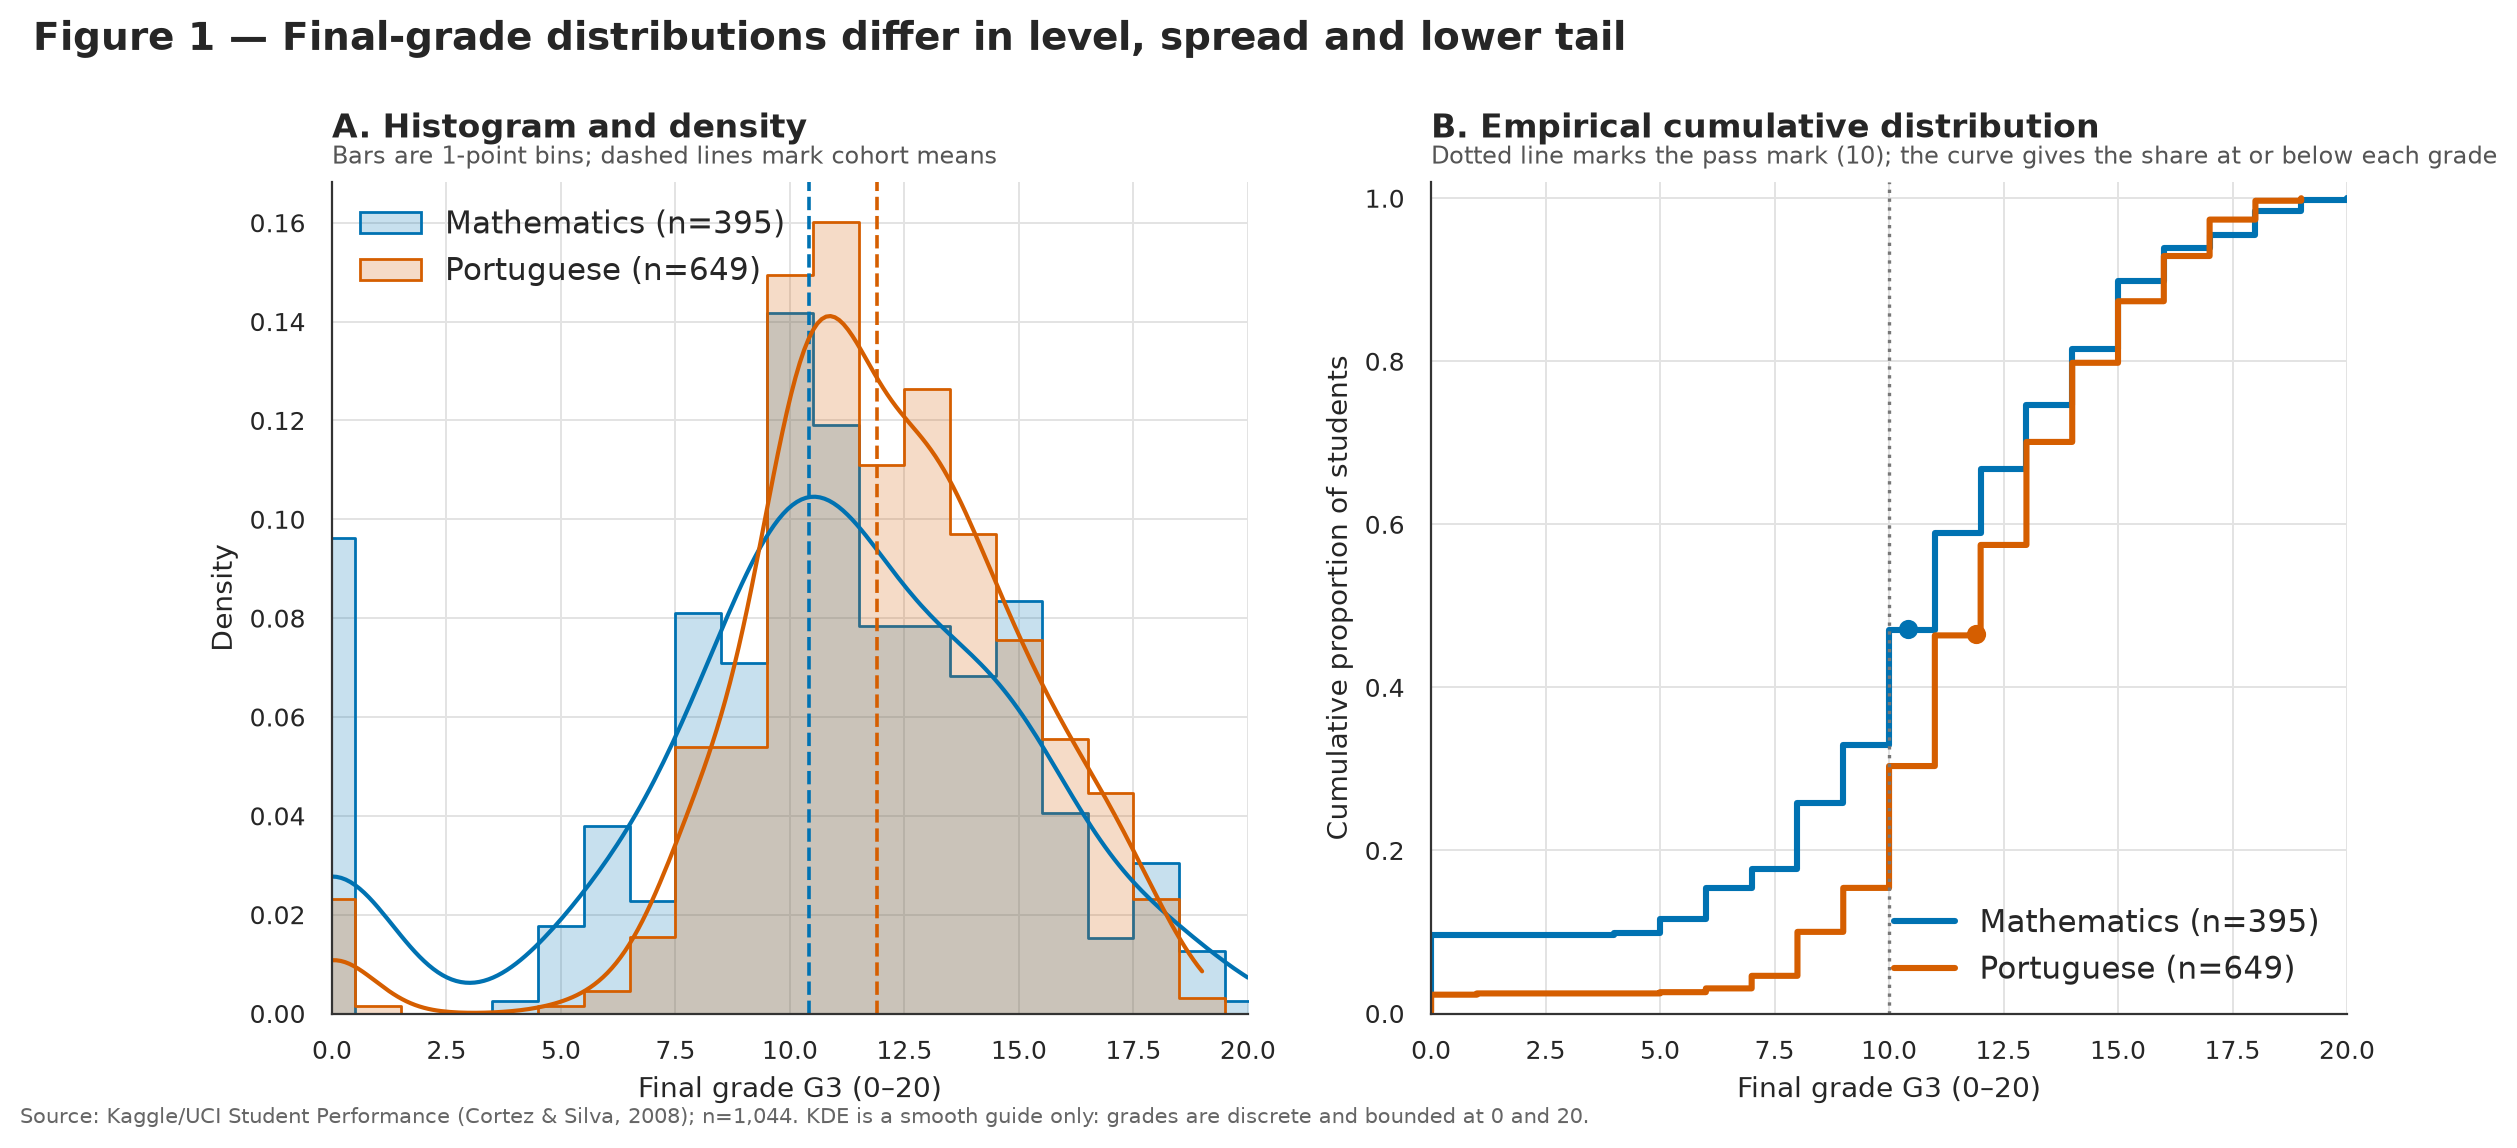

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4))
bins = np.arange(-0.5, 21.5, 1)

ax = axes[0]
for subject in SUBJECTS:
    g = df[df["subject"] == subject]
    sns.histplot(
        data=g, x="G3", bins=bins, stat="density", element="step",
        fill=True, alpha=0.22, color=PAL[subject], kde=True,
        line_kws={"linewidth": 1.5},
        label=f"{subject} (n={len(g)})", ax=ax,
    )
    ax.axvline(g["G3"].mean(), color=PAL[subject], linestyle="--", linewidth=1.3)
ax.set_xlim(0, 20)
ax.set_xlabel("Final grade G3 (0–20)")
ax.set_ylabel("Density")
ax.legend(loc="upper left")
panel_title(ax, "A. Histogram and density",
            "Bars are 1-point bins; dashed lines mark cohort means")

ax = axes[1]
for subject in SUBJECTS:
    g = df[df["subject"] == subject]
    x, y = ecdf(g["G3"])
    ax.step(x, y, where="post", color=PAL[subject], linewidth=2.2,
            label=f"{subject} (n={len(g)})")
    ax.scatter([g["G3"].mean()], [np.interp(g["G3"].mean(), x, y)],
               color=PAL[subject], zorder=5, s=35)
ax.axvline(10, color="#777777", linestyle=":", linewidth=1.2)
ax.set_xlim(0, 20)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Final grade G3 (0–20)")
ax.set_ylabel("Cumulative proportion of students")
ax.legend(loc="lower right")
panel_title(ax, "B. Empirical cumulative distribution",
            "Dotted line marks the pass mark (10); the curve gives the share at or below each grade")
fig.suptitle("Figure 1 — Final-grade distributions differ in level, spread and lower tail",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "01_grade_distributions.png",
           "Source: Kaggle/UCI Student Performance (Cortez & Silva, 2008); n=1,044. "
           "KDE is a smooth guide only: grades are discrete and bounded at 0 and 20.")

display(Image(filename=str(CHARTS / "01_grade_distributions.png"), width=1100))

**What Figure 1 shows.** Both distributions peak around 10–13 and are left-skewed,
but mathematics is flatter and has a pronounced spike at 0. The ECDF makes the gap
easy to read: at any grade below about 15, a larger share of mathematics students
lies at or below that grade. The vertical distance between the curves is largest in
the lower half of the distribution, which is where the cohort difference is concentrated.

**Why these encodings.** The histogram shows shape and the 0 spike; the ECDF shows
the whole distribution without arbitrary bin widths and supports direct statements
such as “67.1% vs 84.6% reached 10”. The dashed means add a summary without hiding
the spread.

**Critique and limits.** A KDE drawn over integer grades can suggest mass between
integer values, and bin width changes the visual impression; the ECDF is the more
honest summary. Neither panel shows uncertainty bands, although the sample sizes are
large. The cohort comparison is descriptive: the two files are different samples, so
the visual gap is not a randomised treatment effect.

## 6. Attendance patterns (Figure 2)

**Question.** How are absences distributed, and is there a monotonic association
between absences and final grades?

Attendance is measured by `absences`, the number of reported school absences. It is a
proxy: it counts absences from school, not absences from a particular class, and it
comes from school records, which may contain reporting error.

,n,mean_absences,median_absences,sd_absences,max_absences,pct_zero,pct_gt20
subject,,,,,,,
Mathematics,395,5.710,4.000,8.000,75,29.110,3.800
Portuguese,649,3.660,2.000,4.640,32,37.600,1.230


,subject,n,pearson_r,pearson_p,spearman_rho,spearman_p,boot_ci_low,boot_ci_high
0,Mathematics,395,0.034,0.497,0.018,0.725,-0.042,0.119
1,Portuguese,649,-0.091,0.020,-0.159,0.000,-0.173,-0.013


,subject,absence_band,n,mean,median,sd,ci95
0,Mathematics,0,115,8.440,10.000,6.470,1.180
1,Mathematics,1-2,68,11.960,11.500,2.960,0.700
2,Mathematics,3-5,66,11.330,11.000,3.240,0.780
3,Mathematics,6-10,80,11.400,11.000,3.230,0.710
4,Mathematics,11-20,51,10.120,10.000,3.000,0.820
5,Mathematics,21+,15,10.270,9.000,3.840,1.950
6,Portuguese,0,244,12.040,13.000,4.070,0.510
7,Portuguese,1-2,122,12.210,12.000,2.560,0.450
8,Portuguese,3-5,112,11.880,11.000,2.520,0.470
9,Portuguese,6-10,122,11.850,11.000,2.660,0.470


Saved chart: charts\02_attendance_patterns.png


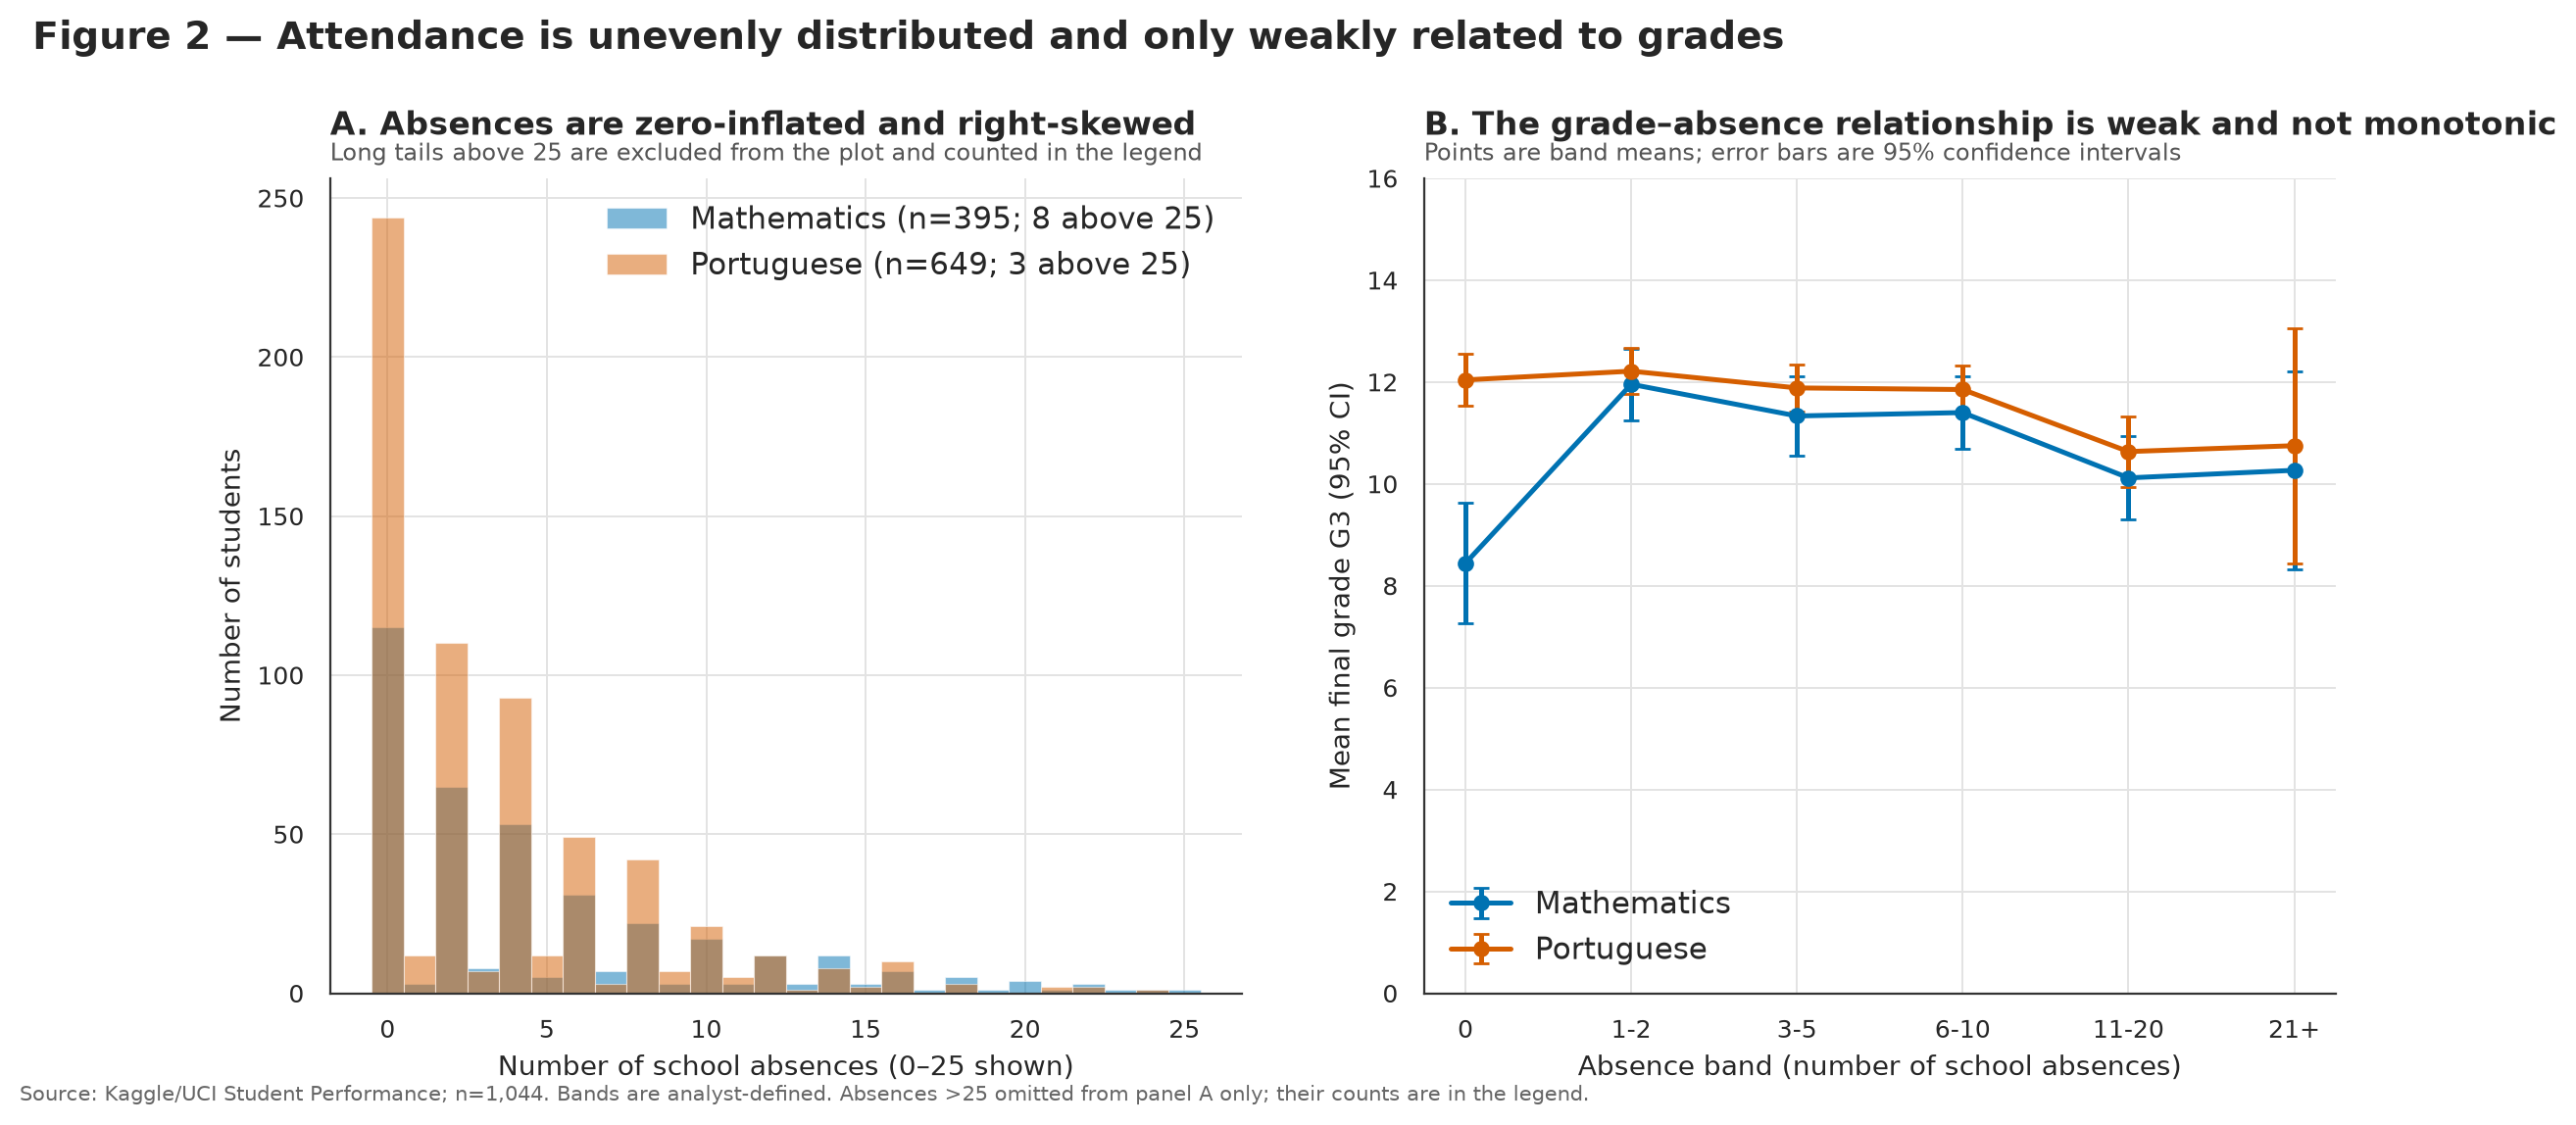

In [6]:
attendance = df.groupby("subject").agg(
    n=("absences", "size"),
    mean_absences=("absences", "mean"),
    median_absences=("absences", "median"),
    sd_absences=("absences", "std"),
    max_absences=("absences", "max"),
    pct_zero=("absences", lambda s: (s == 0).mean() * 100),
    pct_gt20=("absences", lambda s: (s > 20).mean() * 100),
)
display(attendance.round(2))

attendance_tests = []
for subject, g in df.groupby("subject", sort=False):
    r, p = stats.pearsonr(g["absences"], g["G3"])
    rho, p_rho = stats.spearmanr(g["absences"], g["G3"])
    boot = []
    for _ in range(2000):
        idx = RNG.integers(0, len(g), len(g))
        boot.append(np.corrcoef(g["absences"].to_numpy()[idx], g["G3"].to_numpy()[idx])[0, 1])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    attendance_tests.append({
        "subject": subject, "n": len(g), "pearson_r": r, "pearson_p": p,
        "spearman_rho": rho, "spearman_p": p_rho,
        "boot_ci_low": lo, "boot_ci_high": hi,
    })
attendance_tests = pd.DataFrame(attendance_tests)
display(attendance_tests.round(3))

absence_edges = [-1, 0, 2, 5, 10, 20, 200]
absence_labels = ["0", "1-2", "3-5", "6-10", "11-20", "21+"]
df["absence_band"] = pd.cut(df["absences"], bins=absence_edges, labels=absence_labels)
absence_summary = (
    df.groupby(["subject", "absence_band"], observed=True)["G3"]
      .agg(n="size", mean="mean", median="median", sd="std")
      .reset_index()
)
absence_summary["ci95"] = 1.96 * absence_summary["sd"] / np.sqrt(absence_summary["n"])
absence_summary.to_csv(PROC / "attendance_by_band.csv", index=False)
display(absence_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4))
ax = axes[0]
for subject in SUBJECTS:
    g = df[df["subject"] == subject]
    shown = g.loc[g["absences"] <= 25, "absences"]
    ax.hist(shown, bins=np.arange(0, 27) - 0.5, color=PAL[subject], alpha=0.5,
            label=f"{subject} (n={len(g)}; {int((g['absences'] > 25).sum())} above 25)",
            edgecolor="white", linewidth=0.4)
ax.set_xlabel("Number of school absences (0–25 shown)")
ax.set_ylabel("Number of students")
ax.legend(loc="upper right")
panel_title(ax, "A. Absences are zero-inflated and right-skewed",
            "Long tails above 25 are excluded from the plot and counted in the legend")

ax = axes[1]
for subject in SUBJECTS:
    sub = absence_summary[absence_summary["subject"] == subject]
    ax.errorbar(np.arange(len(absence_labels)), sub["mean"], yerr=sub["ci95"],
                marker="o", markersize=5, linewidth=1.8, capsize=3,
                color=PAL[subject], label=subject)
ax.set_xticks(np.arange(len(absence_labels)), absence_labels)
ax.set_xlabel("Absence band (number of school absences)")
ax.set_ylabel("Mean final grade G3 (95% CI)")
ax.set_ylim(0, 16)
ax.legend(loc="lower left")
panel_title(ax, "B. The grade–absence relationship is weak and not monotonic",
            "Points are band means; error bars are 95% confidence intervals")
fig.suptitle("Figure 2 — Attendance is unevenly distributed and only weakly related to grades",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "02_attendance_patterns.png",
           "Source: Kaggle/UCI Student Performance; n=1,044. Bands are analyst-defined. "
           "Absences >25 omitted from panel A only; their counts are in the legend.")

display(Image(filename=str(CHARTS / "02_attendance_patterns.png"), width=1100))

**What Figure 2 shows.** Absences are zero-inflated: 29.1% of mathematics students and
37.6% of Portuguese students have zero recorded absences, while a small tail reaches
75 (mathematics) and 32 (Portuguese). The band means do **not** fall monotonically
with more absences. In mathematics, students with zero absences average 8.44, lower
than the 11.96 average of students with 1–2 absences; the 11–20 band is clearly lower,
while the 21+ band is small (n = 15) and imprecise. In Portuguese the decline is smoother and modest (12.04 at zero,
10.63 at 11–20), but the 21+ band ticks back up.

**Statistical reading.** The Pearson correlation between absences and G3 is +0.034
(p = 0.497) in mathematics and −0.091 (p = 0.020) in Portuguese; the pooled correlation
is −0.046 with a bootstrap 95% interval of −0.103 to +0.009. Even the Portuguese
association is small: absences explain well under 1% of grade variance. The Spearman
coefficient is larger in Portuguese (ρ = −0.159) than Pearson, which is consistent
with a monotonic but non-linear tail rather than a straight-line effect.

**Why this matters for interpretation.** A naive “attendance causes grades” story is
not supported by a simple monotonic pattern here. Low grades can also cause
disengagement and absence (reverse causality), and students who are frequently absent
may differ in health, family circumstances or prior attainment (confounding). The
zero-absence group is not a clean control group: in mathematics it has the lowest mean
grade, which suggests selection rather than a protective effect of perfect attendance.

## 7. Study habits and results (Figure 3)

**Question.** Do reported study time and past failures track final grades, and does
the pattern differ by cohort?

`studytime` is an ordinal band (1 = under 2 hours/week, 2 = 2–5, 3 = 5–10, 4 = over
10). `failures` counts past class failures and is top-coded at 3.

,subject,studytime,n,mean,median,sd,ci95
0,Mathematics,1,105,10.050,10.000,4.960,0.950
1,Mathematics,2,198,10.170,11.000,4.220,0.590
2,Mathematics,3,65,11.400,12.000,4.640,1.130
3,Mathematics,4,27,11.260,12.000,5.280,1.990
4,Portuguese,1,212,10.840,11.000,3.220,0.430
5,Portuguese,2,305,12.090,12.000,3.240,0.360
6,Portuguese,3,97,13.230,13.000,2.500,0.500
7,Portuguese,4,35,13.060,13.000,3.040,1.010


,subject,kruskal_H,kruskal_p,spearman_rho,spearman_p
0,Mathematics,7.579,0.056,0.105,0.037
1,Portuguese,50.316,0.000,0.275,0.000


,subject,failures,n,mean,median,sd,ci95
0,Mathematics,0,312,11.250,11.000,4.170,0.460
1,Mathematics,1,50,8.120,9.000,4.710,1.310
2,Mathematics,2,17,6.240,8.000,4.840,2.300
3,Mathematics,3,16,5.690,7.000,4.190,2.050
4,Portuguese,0,549,12.510,12.000,2.830,0.240
5,Portuguese,1,70,8.640,10.000,3.440,0.810
6,Portuguese,2,16,8.810,9.500,3.210,1.570
7,Portuguese,3,14,8.070,8.500,2.790,1.460


n   mean  median    sd
subject     paid                          
Mathematics no    214  9.990  11.000 5.130
            yes   181 10.920  11.000 3.790
Portuguese  no    610 11.950  12.000 3.250
            yes    39 11.210  12.000 2.850

,subject,n_paid,n_not,mean_paid,mean_not,mannwhitney_p,cohens_d
0,Mathematics,181,214,10.923,9.986,0.227,0.205
1,Portuguese,39,610,11.205,11.951,0.149,-0.231


n   mean  median
subject     higher                    
Mathematics no       20  6.800   8.000
            yes     375 10.610  11.000
Portuguese  no       69  8.800  10.000
            yes     580 12.280  12.000

Saved chart: charts\03_study_habits_grades.png


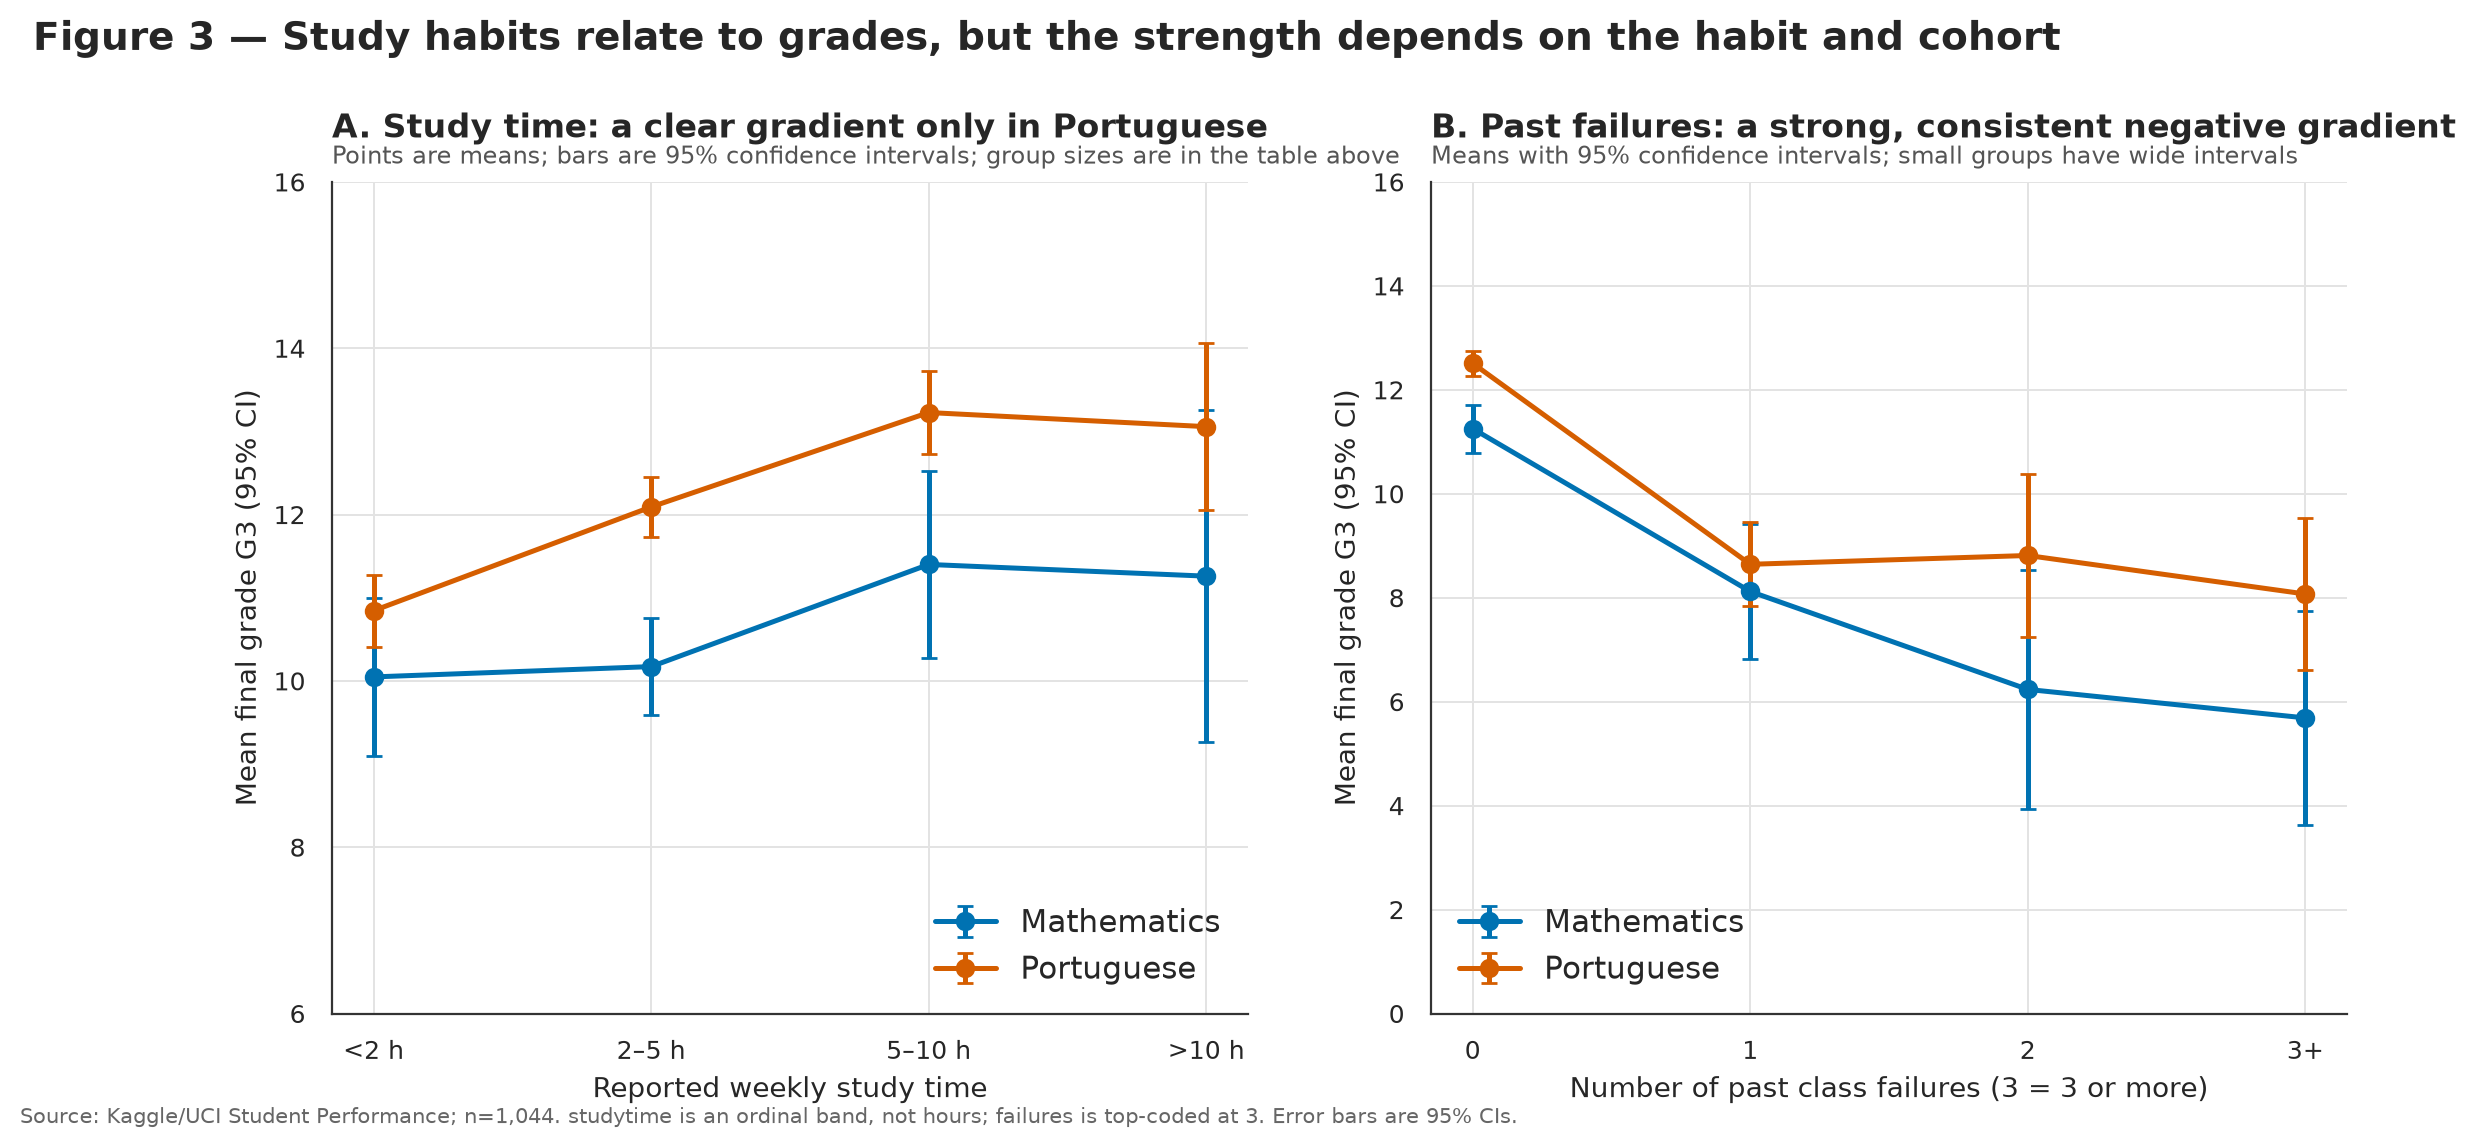

In [7]:
studytime_summary = (
    df.groupby(["subject", "studytime"])["G3"]
      .agg(n="size", mean="mean", median="median", sd="std")
      .reset_index()
)
studytime_summary["ci95"] = 1.96 * studytime_summary["sd"] / np.sqrt(studytime_summary["n"])
display(studytime_summary.round(2))

studytime_tests = []
for subject, g in df.groupby("subject", sort=False):
    groups = [x["G3"].to_numpy() for _, x in g.groupby("studytime")]
    h, p_kw = stats.kruskal(*groups)
    rho, p_rho = stats.spearmanr(g["studytime"], g["G3"])
    studytime_tests.append({"subject": subject, "kruskal_H": h, "kruskal_p": p_kw,
                            "spearman_rho": rho, "spearman_p": p_rho})
studytime_tests = pd.DataFrame(studytime_tests)
display(studytime_tests.round(3))

failure_summary = (
    df.groupby(["subject", "failures"])["G3"]
      .agg(n="size", mean="mean", median="median", sd="std")
      .reset_index()
)
failure_summary["ci95"] = 1.96 * failure_summary["sd"] / np.sqrt(failure_summary["n"])
display(failure_summary.round(2))

paid_summary = df.groupby(["subject", "paid"])["G3"].agg(n="size", mean="mean", median="median", sd="std")
display(paid_summary.round(2))
paid_tests = []
for subject, g in df.groupby("subject", sort=False):
    yes = g.loc[g["paid"] == "yes", "G3"]
    no = g.loc[g["paid"] == "no", "G3"]
    u, p = stats.mannwhitneyu(yes, no)
    paid_tests.append({"subject": subject, "n_paid": len(yes), "n_not": len(no),
                       "mean_paid": yes.mean(), "mean_not": no.mean(),
                       "mannwhitney_p": p, "cohens_d": cohens_d(yes, no)})
paid_tests = pd.DataFrame(paid_tests)
display(paid_tests.round(3))

higher_summary = df.groupby(["subject", "higher"])["G3"].agg(n="size", mean="mean", median="median")
display(higher_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4))
ax = axes[0]
for subject in SUBJECTS:
    sub = studytime_summary[studytime_summary["subject"] == subject]
    ax.errorbar(sub["studytime"], sub["mean"], yerr=sub["ci95"], marker="o",
                markersize=6, linewidth=1.8, capsize=3, color=PAL[subject], label=subject)
ax.set_xticks([1, 2, 3, 4], ["<2 h", "2–5 h", "5–10 h", ">10 h"])
ax.set_xlabel("Reported weekly study time")
ax.set_ylabel("Mean final grade G3 (95% CI)")
ax.set_ylim(6, 16)
ax.legend(loc="lower right")
panel_title(ax, "A. Study time: a clear gradient only in Portuguese",
            "Points are means; bars are 95% confidence intervals; group sizes are in the table above")

ax = axes[1]
for subject in SUBJECTS:
    sub = failure_summary[failure_summary["subject"] == subject]
    ax.errorbar(sub["failures"], sub["mean"], yerr=sub["ci95"], marker="o",
                markersize=6, linewidth=1.8, capsize=3, color=PAL[subject], label=subject)
ax.set_xticks([0, 1, 2, 3], ["0", "1", "2", "3+"])
ax.set_xlabel("Number of past class failures (3 = 3 or more)")
ax.set_ylabel("Mean final grade G3 (95% CI)")
ax.set_ylim(0, 16)
ax.legend(loc="lower left")
panel_title(ax, "B. Past failures: a strong, consistent negative gradient",
            "Means with 95% confidence intervals; small groups have wide intervals")
fig.suptitle("Figure 3 — Study habits relate to grades, but the strength depends on the habit and cohort",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "03_study_habits_grades.png",
           "Source: Kaggle/UCI Student Performance; n=1,044. studytime is an ordinal band, "
           "not hours; failures is top-coded at 3. Error bars are 95% CIs.")

display(Image(filename=str(CHARTS / "03_study_habits_grades.png"), width=1100))

**What Figure 3 shows.** In the Portuguese cohort, mean G3 rises steadily across study
bands: 10.84 (<2 h), 12.09 (2–5 h), 13.23 (5–10 h) and 13.06 (>10 h). The Kruskal–Wallis
test rejects equal distributions (p < 0.001) and Spearman ρ = 0.275. In mathematics the
pattern is much weaker: 10.05, 10.17, 11.40 and 11.26, with Kruskal–Wallis p = 0.056
and Spearman ρ = 0.105 (p = 0.037). The last band has only 27 mathematics students, so
its mean is imprecise.

Past failures show a stronger and more consistent pattern in both cohorts. Students
with no failures average 11.25 (mathematics) and 12.51 (Portuguese); students with
three or more average 5.69 and 8.07. Spearman ρ is −0.361 in mathematics and −0.448 in
Portuguese. The groups with two or three failures are small (14–17 students), which is
why their confidence intervals are wide.

**Paid classes.** Raw grade differences by paid tuition are small and not statistically
significant: mathematics 10.92 with paid classes vs 9.99 without (Mann–Whitney
p = 0.227, d = 0.21); Portuguese 11.21 vs 11.95 (p = 0.149, d = −0.23). This is not
evidence that tutoring does not work. Uptake is very different between cohorts (45.8%
vs 6.0%) and is chosen by families, so the comparison is confounded by prior
attainment, motivation and resources.

**Critique and limits.** The ordinal bands are treated as equally spaced on the x-axis,
which is a visual convenience, not a measurement assumption; the plotted values are
group means, so within-band spread is hidden. The study-time measure is self-reported
and coarse, and “more study time” may be a response to struggling rather than a cause
of higher grades. These are associational patterns.

## 8. Sampling differences and possible bias (Figure 4)

**Question.** How do the two cohorts differ in composition, and what does that imply
for comparisons between them?

The dataset is not one random sample. It contains two subject-specific cohorts from
Portuguese secondary schools, collected through school records and questionnaires.
The composition of those cohorts is itself informative.

,metric,Mathematics,Portuguese,difference_pp
0,Attends MS school,11.650,34.820,23.180
1,Paid classes,45.820,6.010,-39.810
2,Female,52.660,59.010,6.360
3,Wants higher education,94.940,89.370,-5.570
4,Home internet,83.290,76.730,-6.560
5,Rural address,22.280,30.350,8.080


Sex composition chi-square: chi2 = 3.783 df = 1 p = 0.052


sex,F,M
subject,,
Mathematics,208,187
Portuguese,383,266


,variable,math_mean,por_mean,difference,welch_t,welch_p,mannwhitney_p,cohens_d
0,G3,10.415,11.906,-1.491,-5.666,0.000,0.000,-0.392
1,absences,5.709,3.659,2.049,4.637,0.000,0.000,NaN
2,studytime,2.035,1.931,0.105,1.965,0.050,0.041,NaN


,subject,school,n,mean,median,sd,ci95
0,Mathematics,GP,349,10.490,11.000,4.630,0.490
1,Mathematics,MS,46,9.850,10.000,4.240,1.220
2,Portuguese,GP,423,12.580,13.000,2.630,0.250
3,Portuguese,MS,226,10.650,11.000,3.830,0.500


School-mix-standardised mean G3: {'Mathematics': 10.323, 'Portuguese': 12.075}
Standardised gap (Portuguese - Mathematics): 1.752


,value
matched_rows_using_original_R_keys,382.000
distinct_math_grade_triples_in_matches,187.000
corr_math_vs_por_G3_in_matches,0.480
corr_absences_in_matches,0.497


Saved chart: charts\04_sampling_comparison.png


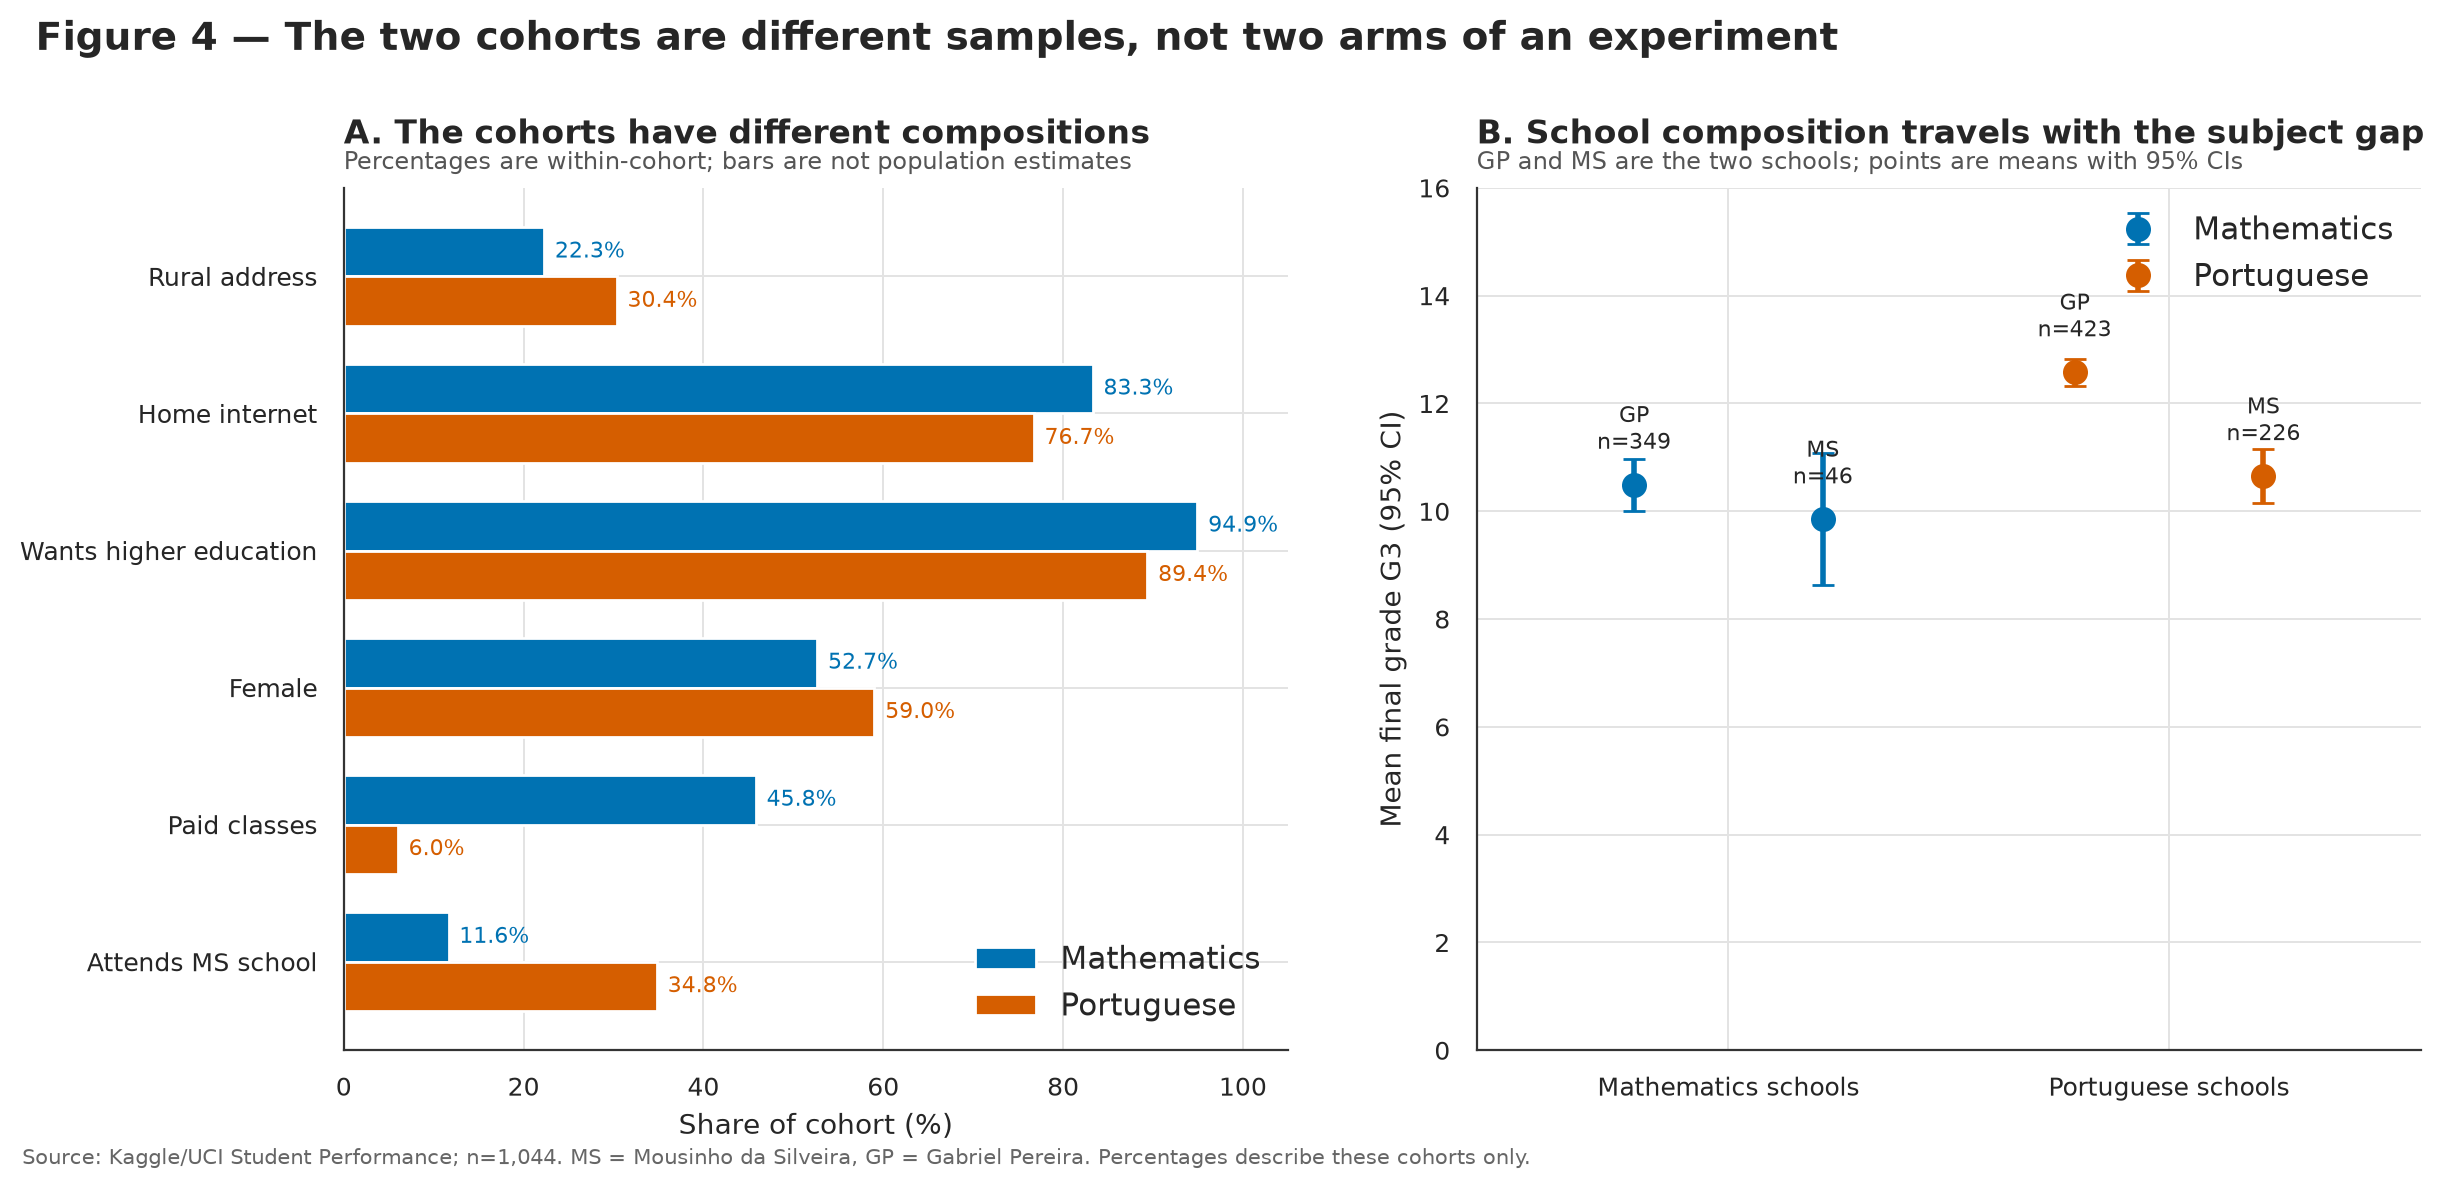

In [8]:
composition_rows = []
for metric, level, label in [
    ("school", "MS", "Attends MS school"),
    ("paid", "yes", "Paid classes"),
    ("sex", "F", "Female"),
    ("higher", "yes", "Wants higher education"),
    ("internet", "yes", "Home internet"),
    ("address", "R", "Rural address"),
]:
    values = df.groupby("subject")[metric].apply(lambda s, level=level: (s == level).mean() * 100)
    composition_rows.append({"metric": label, "Mathematics": values["Mathematics"],
                             "Portuguese": values["Portuguese"]})
composition = pd.DataFrame(composition_rows)
composition["difference_pp"] = composition["Portuguese"] - composition["Mathematics"]
display(composition.round(2))

sex_table = pd.crosstab(df["subject"], df["sex"])
chi2, p_sex, dof, expected = stats.chi2_contingency(sex_table)
print("Sex composition chi-square: chi2 =", round(chi2, 3), "df =", dof, "p =", fmt_p(p_sex))
display(sex_table)

cohort_tests = []
for variable in ["G3", "absences", "studytime"]:
    a = mat[variable].to_numpy(dtype=float)
    b = por[variable].to_numpy(dtype=float)
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    u, p_u = stats.mannwhitneyu(a, b)
    cohort_tests.append({
        "variable": variable, "math_mean": a.mean(), "por_mean": b.mean(),
        "difference": a.mean() - b.mean(), "welch_t": t, "welch_p": p_t,
        "mannwhitney_p": p_u,
        "cohens_d": cohens_d(a, b) if variable == "G3" else np.nan,
    })
cohort_tests = pd.DataFrame(cohort_tests)
display(cohort_tests.round(3))

school_summary = (
    df.groupby(["subject", "school"])["G3"]
      .agg(n="size", mean="mean", median="median", sd="std")
      .reset_index()
)
school_summary["ci95"] = 1.96 * school_summary["sd"] / np.sqrt(school_summary["n"])
display(school_summary.round(2))

school_share = df["school"].value_counts(normalize=True)
standardised_means = {}
for subject in SUBJECTS:
    sub = school_summary[school_summary["subject"] == subject].set_index("school")
    standardised_means[subject] = float(sum(school_share[s] * sub.loc[s, "mean"] for s in school_share.index))
print("School-mix-standardised mean G3:",
      {k: round(v, 3) for k, v in standardised_means.items()})
print("Standardised gap (Portuguese - Mathematics):",
      round(standardised_means["Portuguese"] - standardised_means["Mathematics"], 3))

match_keys = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu",
              "Mjob", "Fjob", "reason", "nursery", "internet"]
matched = mat.merge(por, on=match_keys, suffixes=("_mat", "_por"))
overlap = {
    "matched_rows_using_original_R_keys": int(len(matched)),
    "distinct_math_grade_triples_in_matches": int(matched[["G1_mat", "G2_mat", "G3_mat"]].drop_duplicates().shape[0]),
    "corr_math_vs_por_G3_in_matches": float(np.corrcoef(matched["G3_mat"], matched["G3_por"])[0, 1]),
    "corr_absences_in_matches": float(np.corrcoef(matched["absences_mat"], matched["absences_por"])[0, 1]),
}
display(pd.Series(overlap, name="value").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.6))
ax = axes[0]
y = np.arange(len(composition))
height = 0.36
ax.barh(y + height / 2, composition["Mathematics"], height=height, color=PAL["Mathematics"], label="Mathematics")
ax.barh(y - height / 2, composition["Portuguese"], height=height, color=PAL["Portuguese"], label="Portuguese")
for i, row in composition.iterrows():
    ax.text(row["Mathematics"] + 1.2, i + height / 2, f"{row['Mathematics']:.1f}%",
            va="center", fontsize=8, color=PAL["Mathematics"])
    ax.text(row["Portuguese"] + 1.2, i - height / 2, f"{row['Portuguese']:.1f}%",
            va="center", fontsize=8, color=PAL["Portuguese"])
ax.set_yticks(y, composition["metric"])
ax.set_xlim(0, 105)
ax.set_xlabel("Share of cohort (%)")
ax.legend(loc="lower right")
panel_title(ax, "A. The cohorts have different compositions",
            "Percentages are within-cohort; bars are not population estimates")

ax = axes[1]
positions = {"Mathematics": 0, "Portuguese": 0.42}
for subject in SUBJECTS:
    sub = school_summary[school_summary["subject"] == subject]
    xs = [positions[subject] + i * 0.18 for i in range(len(sub))]
    ax.errorbar(xs, sub["mean"], yerr=sub["ci95"], fmt="o", markersize=8,
                capsize=4, linewidth=2, color=PAL[subject], label=subject)
    for x, (_, row) in zip(xs, sub.iterrows()):
        ax.annotate(f"{row['school']}\nn={int(row['n'])}", (x, row["mean"]),
                    textcoords="offset points", xytext=(0, 13), ha="center", fontsize=8)
ax.set_xticks([0.09, 0.51], ["Mathematics schools", "Portuguese schools"])
ax.set_xlim(-0.15, 0.75)
ax.set_ylim(0, 16)
ax.set_ylabel("Mean final grade G3 (95% CI)")
ax.legend(loc="upper right")
panel_title(ax, "B. School composition travels with the subject gap",
            "GP and MS are the two schools; points are means with 95% CIs")
fig.suptitle("Figure 4 — The two cohorts are different samples, not two arms of an experiment",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "04_sampling_comparison.png",
           "Source: Kaggle/UCI Student Performance; n=1,044. MS = Mousinho da Silveira, "
           "GP = Gabriel Pereira. Percentages describe these cohorts only.")

display(Image(filename=str(CHARTS / "04_sampling_comparison.png"), width=1100))

**What Figure 4 shows.** The Portuguese cohort contains a much larger share of students
from the MS school (34.8% vs 11.6%), more students with rural addresses (30.4% vs
22.3%), and far fewer students taking paid classes (6.0% vs 45.8%). Sex composition
differs modestly (59.0% female vs 52.7%; chi-square p = 0.052).

**Why the raw grade gap is not a subject effect.** The raw difference is 1.49 grade
points (Portuguese higher). Within the GP school the gap is 2.09 points (12.58 vs
10.49); within the MS school it is only 0.80 points (10.65 vs 9.85). Standardising both
cohorts to the same school mix raises the gap to about 1.75 points. School
composition is entangled with subject cohort, and the schools themselves may differ in
intake and resources (not measured here). The data cannot separate “Portuguese is graded more generously”
from “the Portuguese cohort contains different students”.

**Overlap and non-independence.** Applying the matching keys from the original
`student-merge.R` script produces 382 matched rows, consistent with the dataset
documentation. But the merge is many-to-many: those 382 rows contain only 187 distinct
mathematics grade triples, because several students share the same background profile.
The matched mathematics and Portuguese grades correlate at 0.48, and absences at 0.50.
Treating all 1,044 rows as independent observations would therefore overstate the
effective sample size, and treating the 382 matches as a clean paired panel would be
wrong. This project keeps the cohorts separate for inference and uses pooled figures
only as descriptive summaries with the cohort shown.

**Sampling limitations.** This is a convenience sample of two Portuguese schools, not
a random sample of Portuguese students, let alone students elsewhere. Participation,
school choice and subject enrolment are not random. Estimates of levels and
correlations may not generalise; comparisons between cohorts are confounded by school,
intake and selection into paid tuition. These limitations are about *generalisation and
causality*, not about arithmetic: the descriptive statistics are correct for these 1,044
records.

## 9. Correlation analysis (Figure 5)

**Question.** Which variables move with final grades, how strong are the associations,
and what can and cannot be concluded from them?

The heatmaps show Spearman rank correlations separately for each cohort. Spearman is
used because several variables are ordinal or skewed; Pearson values and hypothesis
tests are reported alongside in the tables.

,variable,pearson_r,pearson_p,spearman_rho,spearman_p,n,bh_q
1,G2,0.911,0.000,0.952,0.000,1044,0.000
0,G1,0.809,0.000,0.884,0.000,1044,0.000
3,studytime,0.162,0.000,0.190,0.000,1044,0.000
10,famrel,0.054,0.079,0.049,0.111,1044,0.086
2,absences,-0.046,0.140,-0.109,0.000,1044,0.140
9,health,-0.080,0.010,-0.081,0.009,1044,0.012
6,goout,-0.098,0.002,-0.120,0.000,1044,0.002
8,Walc,-0.116,0.000,-0.149,0.000,1044,0.000
5,age,-0.125,0.000,-0.110,0.000,1044,0.000
7,Dalc,-0.130,0.000,-0.172,0.000,1044,0.000


Bootstrap 95% CIs for pooled Pearson correlations with G3 (2,000 resamples)


,variable,pearson_r,ci_low,ci_high
0,G2,0.911,0.893,0.928
1,absences,-0.046,-0.103,0.009
2,studytime,0.162,0.098,0.220
3,failures,-0.383,-0.438,-0.327


Saved chart: charts\05_correlation_heatmap.png


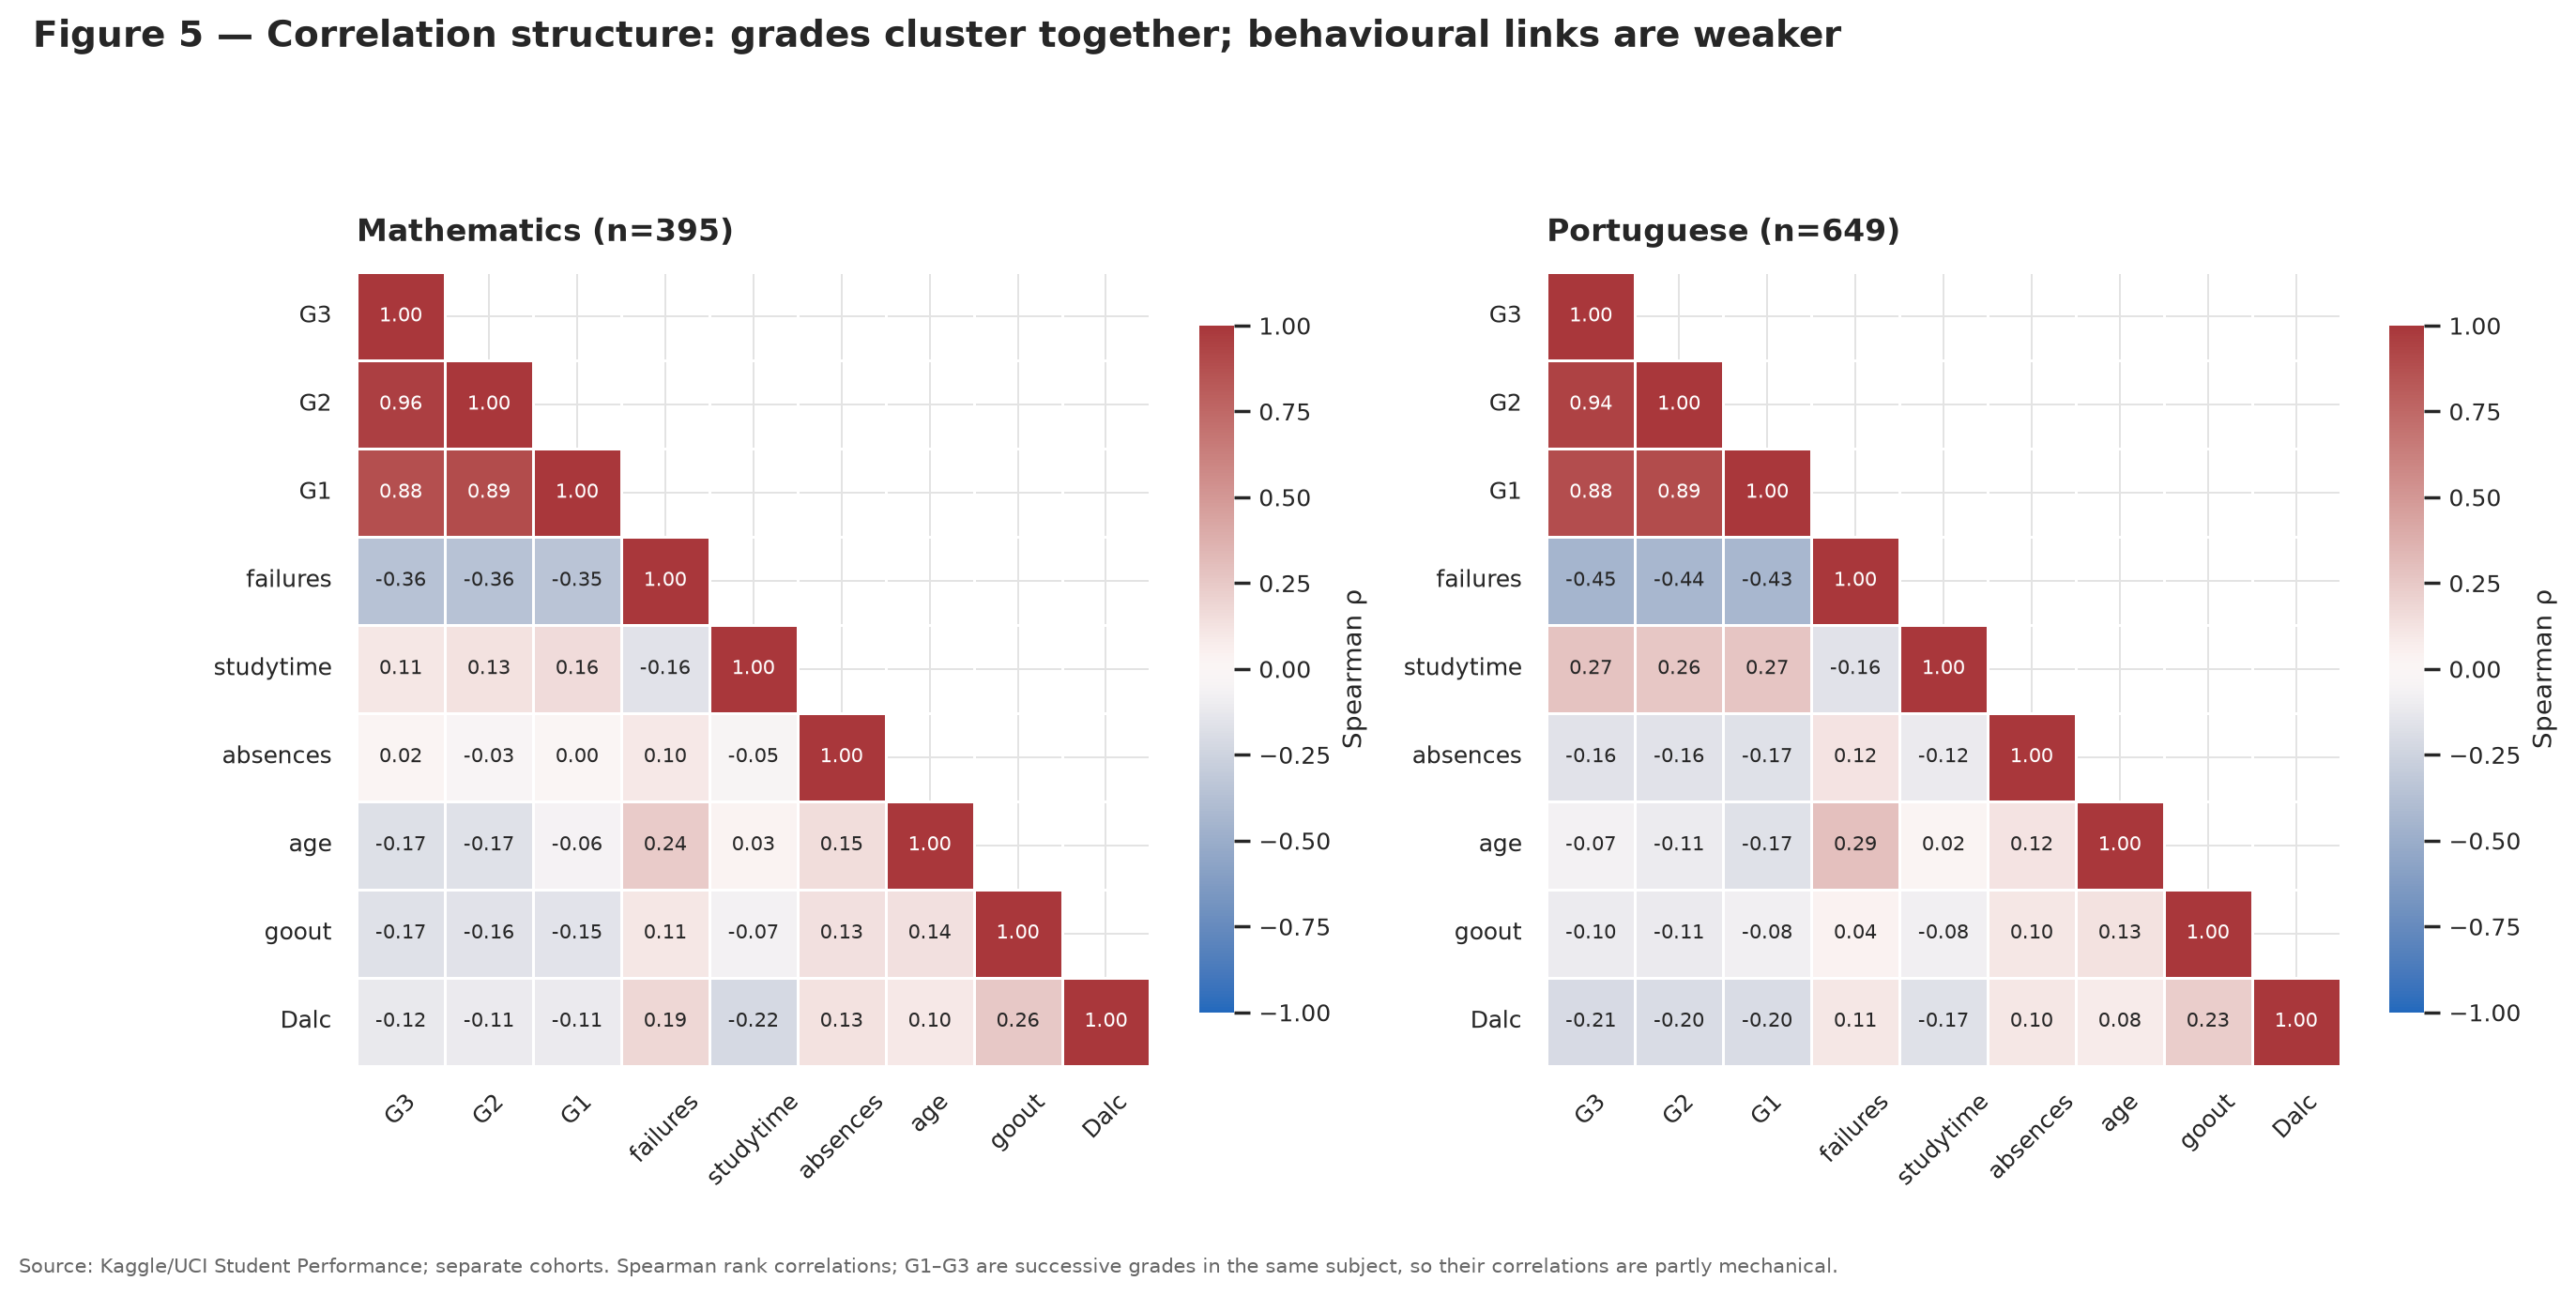

In [9]:
heat_vars = ["G3", "G2", "G1", "failures", "studytime", "absences", "age", "goout", "Dalc"]
pearson_by_subject = {s: df[df["subject"] == s][heat_vars].corr(method="pearson") for s in SUBJECTS}
spearman_by_subject = {s: df[df["subject"] == s][heat_vars].corr(method="spearman") for s in SUBJECTS}

pearson_by_subject["Mathematics"].to_csv(PROC / "correlation_pearson_math.csv")
pearson_by_subject["Portuguese"].to_csv(PROC / "correlation_pearson_portuguese.csv")
spearman_by_subject["Mathematics"].to_csv(PROC / "correlation_spearman_math.csv")
spearman_by_subject["Portuguese"].to_csv(PROC / "correlation_spearman_portuguese.csv")

test_rows = []
for variable in ["G1", "G2", "absences", "studytime", "failures", "age", "goout",
                 "Dalc", "Walc", "health", "famrel"]:
    r, p = stats.pearsonr(df[variable], df["G3"])
    rho, p_rho = stats.spearmanr(df[variable], df["G3"])
    test_rows.append({"variable": variable, "pearson_r": r, "pearson_p": p,
                      "spearman_rho": rho, "spearman_p": p_rho, "n": len(df)})
correlation_tests = pd.DataFrame(test_rows)
correlation_tests["bh_q"] = bh_adjust(correlation_tests["pearson_p"])
correlation_tests = correlation_tests.sort_values("pearson_r", ascending=False)
correlation_tests.to_csv(PROC / "correlation_tests_pooled.csv", index=False)
display(correlation_tests.round(3))

print("Bootstrap 95% CIs for pooled Pearson correlations with G3 (2,000 resamples)")
boot_rows = []
for variable in ["G2", "absences", "studytime", "failures"]:
    x = df[variable].to_numpy(dtype=float)
    y = df["G3"].to_numpy(dtype=float)
    estimates = []
    for _ in range(2000):
        idx = RNG.integers(0, len(df), len(df))
        estimates.append(np.corrcoef(x[idx], y[idx])[0, 1])
    lo, hi = np.percentile(estimates, [2.5, 97.5])
    boot_rows.append({"variable": variable, "pearson_r": np.corrcoef(x, y)[0, 1],
                      "ci_low": lo, "ci_high": hi})
bootstrap_corr = pd.DataFrame(boot_rows)
display(bootstrap_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15.0, 6.6))
for ax, subject in zip(axes, SUBJECTS):
    corr = spearman_by_subject[subject]
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor="white",
                cbar_kws={"shrink": 0.72, "label": "Spearman ρ"},
                annot_kws={"size": 7.4}, ax=ax)
    ax.set_title(f"{subject} (n={len(df[df['subject'] == subject])})", loc="left", pad=12)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Figure 5 — Correlation structure: grades cluster together; behavioural links are weaker",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
save_chart(fig, "05_correlation_heatmap.png",
           "Source: Kaggle/UCI Student Performance; separate cohorts. Spearman rank correlations; "
           "G1–G3 are successive grades in the same subject, so their correlations are partly mechanical.")

display(Image(filename=str(CHARTS / "05_correlation_heatmap.png"), width=1150))

**Reading the matrix.** The strongest cells are the G1–G2–G3 block: in both cohorts,
G2 and G3 correlate at about 0.91–0.92 and G1 and G3 at about 0.80–0.83. These are
grades from successive assessment periods in the same subject, so the correlation is
partly built into the measurement design: a student who performed well in period 2 is
likely to perform well in period 3. It is not evidence that “period 2 causes period 3”.

Outside that block, the clearest associates of G3 are `failures` (ρ ≈ −0.36 mathematics,
−0.45 Portuguese) and, in Portuguese only, `studytime` (ρ ≈ 0.28). `absences` is close
to zero in mathematics and weak in Portuguese. Age, going out and alcohol consumption
show small negative correlations; family relationship quality is essentially unrelated
in this sample.

**Significance is not importance.** With n = 1,044, small correlations can be
“statistically significant”. The pooled table therefore includes Benjamini–Hochberg
q-values for the 11 tests involving G3. `studytime` and `failures` survive correction;
`absences` does not (q = 0.14). The 95% bootstrap interval for the pooled
grade–absence correlation, −0.103 to +0.009, includes zero. Always read the effect
size and interval before the p-value.

**Why correlation is not causation.** Six concrete reasons in this dataset:

1. **Reverse causality.** Low grades may cause disengagement, which causes absence;
   the direction is not identified by a correlation.
2. **Confounding.** Prior attainment, motivation, family resources and school quality
   can drive both study habits and grades. `failures` is itself a prior-attainment
   marker, not a clean behavioural lever.
3. **Selection.** Students choose paid tuition, subject streams and schools. The 45.8%
   vs 6.0% paid-class uptake is a selection pattern, not a treatment assignment.
4. **Mechanical dependence.** G1, G2 and G3 are successive grades of the same course.
   Their correlation is partly definitional.
5. **Chance and multiple testing.** Eleven correlations with G3 were examined; at
   α = 0.05 roughly one false positive is expected before correction.
6. **Non-linearity and outliers.** Absences are zero-inflated with a 75-absence
   outlier; a single Pearson coefficient cannot capture that shape.

A causal claim would require a design that identifies the effect — randomisation,
a natural experiment, or at least careful longitudinal adjustment. None is available
here, so this notebook uses associational language throughout.

## 10. Vectors, matrices and similarity intuition

This section makes the linear algebra concrete using the dataset itself.

**A student is a vector.** Choose five features — G1, G2, G3, absences and studytime.
Each student is then a point in five-dimensional space,
`x = (x₁, x₂, x₃, x₄, x₅)`. The dot product `x · y = Σ xᵢyᵢ` measures alignment;
the norm `||x|| = √(x · x)` measures length; cosine similarity
`cos θ = (x · y) / (||x|| ||y||)` measures the angle between two students' profiles,
independent of their overall magnitude.

**The dataset is a matrix.** Stack the n students as rows: `X` is an n × p matrix
(n = 1,044, p = 5). Its transpose `Xᵀ` is p × n. The product `XᵀX` is a p × p matrix of
sums of squares and cross-products. After centring and scaling each column, dividing
`ZᵀZ` by `n − 1` gives the correlation matrix. In other words, **the correlation matrix
is a normalised Gram matrix**: correlations are cosines between centred variable
vectors.

**Similarity is a choice, not a fact.** Raw cosine similarity on non-negative features
is high for almost everyone because all values are positive; standardising changes who
counts as “similar”. Euclidean distance is scale-dependent. A similarity score is only
meaningful together with the feature set, the scaling and the question being asked.

In [10]:
vector_features = ["G1", "G2", "G3", "absences", "studytime"]
student_a = df.loc[df["student_id"] == "MAT-001", vector_features].iloc[0].to_numpy(dtype=float)
student_b = df.loc[df["student_id"] == "MAT-019", vector_features].iloc[0].to_numpy(dtype=float)

dot = float(student_a @ student_b)
norm_a = float(np.linalg.norm(student_a))
norm_b = float(np.linalg.norm(student_b))
cosine_raw = dot / (norm_a * norm_b)
euclidean = float(np.linalg.norm(student_a - student_b))
centered_a = student_a - student_a.mean()
centered_b = student_b - student_b.mean()
cosine_centered = float(centered_a @ centered_b / (np.linalg.norm(centered_a) * np.linalg.norm(centered_b)))

vector_table = pd.DataFrame({
    "feature": vector_features,
    "MAT-001": student_a,
    "MAT-019": student_b,
    "difference": student_a - student_b,
})
display(vector_table)
display(pd.Series({
    "dot product": dot,
    "norm MAT-001": norm_a,
    "norm MAT-019": norm_b,
    "cosine similarity (raw)": cosine_raw,
    "Euclidean distance": euclidean,
    "cosine similarity (centred profiles)": cosine_centered,
}, name="value").to_frame().round(3))

X = df[vector_features].to_numpy(dtype=float)
X_centered = X - X.mean(axis=0)
X_standardised = X_centered / X.std(axis=0, ddof=1)
gram = X_standardised.T @ X_standardised / (len(X) - 1)
correlation_matrix = df[vector_features].corr().to_numpy()

print(f"X shape: {X.shape}  (n students x p features)")
print(f"X.T shape: {X.T.shape}")
print(f"X.T @ X shape: {X.T @ X}")
print(f"rank(X): {np.linalg.matrix_rank(X)}")
print(f"singular values of standardised X: {np.round(np.linalg.svd(X_standardised, compute_uv=False), 3)}")
print(f"condition number: {np.linalg.cond(X_standardised):.3f}")
print(f"trace of correlation matrix: {np.trace(gram):.6f}")
print(f"max |Gram - pandas correlation|: {np.abs(gram - correlation_matrix).max():.2e}")
display(pd.DataFrame(gram, index=vector_features, columns=vector_features).round(3))

,feature,MAT-001,MAT-019,difference
0,G1,5.000,6.000,-1.000
1,G2,6.000,5.000,1.000
2,G3,6.000,5.000,1.000
3,absences,6.000,16.000,-10.000
4,studytime,2.000,1.000,1.000


,value
dot product,188.000
norm MAT-001,11.705
norm MAT-019,18.520
cosine similarity (raw),0.867
Euclidean distance,10.198
cosine similarity (centred profiles),0.593


X shape: (1044, 5)  (n students x p features)
X.T shape: (5, 1044)
X.T @ X shape: [[140561. 140437. 142511.  50133.  23615.]
 [140437. 143297. 145226.  50169.  23657.]
 [142511. 145226. 149879.  51370.  23874.]
 [ 50133.  50169.  51370.  60756.   8714.]
 [ 23615.  23657.  23874.   8714.   4779.]]
rank(X): 5
singular values of standardised X: [53.935 32.685 30.806 14.297  9.185]
condition number: 5.872
trace of correlation matrix: 5.000000
max |Gram - pandas correlation|: 8.88e-16


,G1,G2,G3,absences,studytime
G1,1.000,0.859,0.809,-0.092,0.211
G2,0.859,1.000,0.911,-0.089,0.183
G3,0.809,0.911,1.000,-0.046,0.162
absences,-0.092,-0.089,-0.046,1.000,-0.076
studytime,0.211,0.183,0.162,-0.076,1.000


**Worked vector example.** MAT-001 has grades (5, 6, 6) with 6 absences and studytime
band 2. MAT-019 has grades (6, 5, 5) with 16 absences and studytime band 1. Their raw
cosine similarity is about 0.87 — the vectors point in a similar direction because
both have low grades and small study time. After centring each student's profile, the
similarity changes, because centring removes the common level and compares only the
*shape* of the profile. This is exactly the difference between “both scored low” and
“both have the same pattern across features”.

**Worked matrix example.** The Gram matrix computed from the standardised 1,044 × 5
matrix matches pandas' correlation matrix to machine precision, and its trace equals 5
(the number of standardised variables). The singular values summarise how much
variation lies along each independent direction; the condition number (about 5.9)
shows that the five features are not nearly collinear enough to make the matrix
numerically unstable, even though G1–G3 are strongly correlated.

Student-pair cosine similarity: mean=0.005, min=-1.000, max=1.000


,absolute G3 difference,pairs,mean cosine similarity
0,0,50047,0.345
1,1,90750,0.291
2,2-3,155088,0.135
3,4-5,106205,-0.134
4,6-7,59263,-0.364
5,8-20,83093,-0.312


Saved chart: charts\06_vector_similarity.png


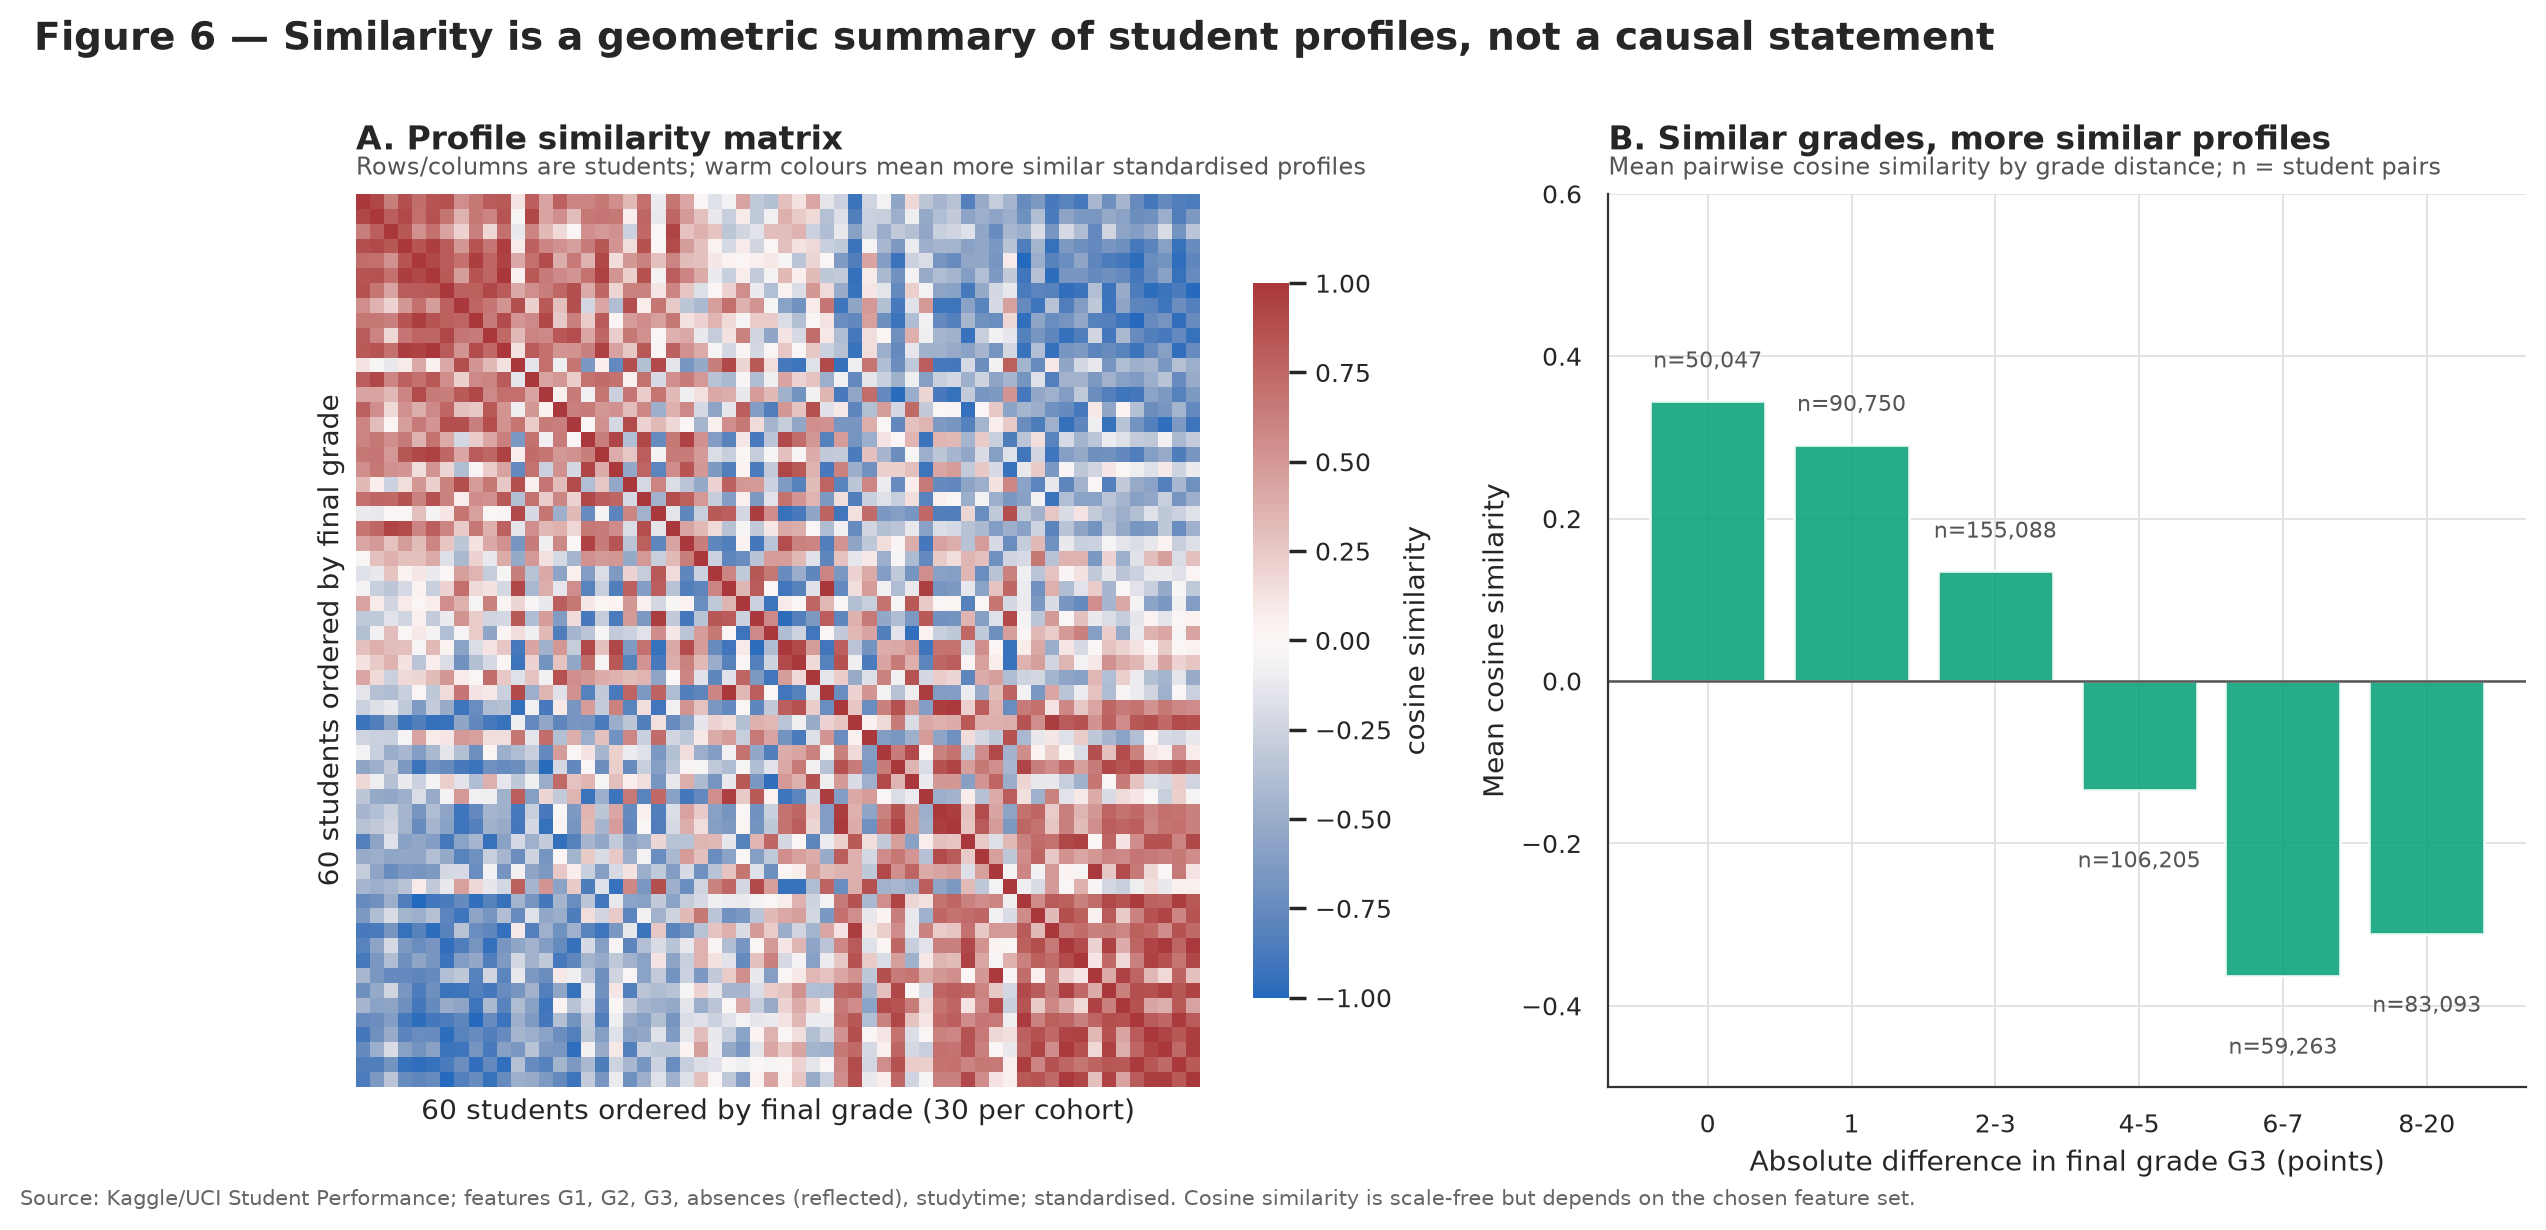

In [11]:
# Full pairwise cosine similarity between student profiles, after standardising features
# and reflecting absences so that larger values always mean "more of the favourable trait".
sim_frame = df[vector_features].copy()
sim_frame["absences"] = -sim_frame["absences"]
S = sim_frame.to_numpy(dtype=float)
S = (S - S.mean(axis=0)) / S.std(axis=0, ddof=1)
row_norms = np.linalg.norm(S, axis=1)
cosine_matrix = (S @ S.T) / np.outer(row_norms, row_norms)
np.fill_diagonal(cosine_matrix, np.nan)

grade_values = df["G3"].to_numpy(dtype=float)
grade_distance = np.abs(grade_values[:, None] - grade_values[None, :])
upper = np.triu_indices(len(df), k=1)
cos_values = cosine_matrix[upper]
distance_values = grade_distance[upper]

print(f"Student-pair cosine similarity: mean={np.nanmean(cos_values):.3f}, "
      f"min={np.nanmin(cos_values):.3f}, max={np.nanmax(cos_values):.3f}")

bands = [(0, 0), (1, 1), (2, 3), (4, 5), (6, 7), (8, 20)]
band_rows = []
for low, high in bands:
    mask = (distance_values >= low) & (distance_values <= high)
    label = f"{low}" if low == high else f"{low}-{high}"
    band_rows.append({"absolute G3 difference": label, "pairs": int(mask.sum()),
                      "mean cosine similarity": float(cos_values[mask].mean())})
band_table = pd.DataFrame(band_rows)
display(band_table.round(3))

selected_ids = []
for subject in SUBJECTS:
    g = df[df["subject"] == subject].sort_values("G3")
    positions = np.linspace(0, len(g) - 1, 30).round().astype(int)
    selected_ids.extend(g.iloc[positions]["student_id"].tolist())
selected = df.set_index("student_id").loc[selected_ids]
selected = selected.sort_values(["G3", "subject"], kind="mergesort")

selected_features = selected[vector_features].copy()
selected_features["absences"] = -selected_features["absences"]
Zsel = selected_features.to_numpy(dtype=float)
Zsel = (Zsel - Zsel.mean(axis=0)) / Zsel.std(axis=0, ddof=1)
norms = np.linalg.norm(Zsel, axis=1)
similarity_selected = (Zsel @ Zsel.T) / np.outer(norms, norms)

fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
sns.heatmap(similarity_selected, cmap="vlag", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, ax=ax,
            cbar_kws={"shrink": 0.8, "label": "cosine similarity"})
ax.set_xlabel("60 students ordered by final grade (30 per cohort)")
ax.set_ylabel("60 students ordered by final grade")
panel_title(ax, "A. Profile similarity matrix",
            "Rows/columns are students; warm colours mean more similar standardised profiles")

ax = axes[1]
ax.bar(np.arange(len(band_table)), band_table["mean cosine similarity"], color=ACCENT, alpha=0.85)
for i, row in band_table.iterrows():
    value = row["mean cosine similarity"]
    offset = 0.035 if value >= 0 else -0.075
    ax.text(i, value + offset, f"n={row['pairs']:,}",
            ha="center", va="bottom" if value >= 0 else "top", fontsize=7.8, color=MUTED)
ax.axhline(0, color="#555555", linewidth=0.9)
ax.set_xticks(np.arange(len(band_table)), band_table["absolute G3 difference"])
ax.set_xlabel("Absolute difference in final grade G3 (points)")
ax.set_ylabel("Mean cosine similarity")
ax.set_ylim(-0.5, 0.6)
panel_title(ax, "B. Similar grades, more similar profiles",
            "Mean pairwise cosine similarity by grade distance; n = student pairs")
fig.suptitle("Figure 6 — Similarity is a geometric summary of student profiles, not a causal statement",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "06_vector_similarity.png",
           "Source: Kaggle/UCI Student Performance; features G1, G2, G3, absences (reflected), studytime; "
           "standardised. Cosine similarity is scale-free but depends on the chosen feature set.")

display(Image(filename=str(CHARTS / "06_vector_similarity.png"), width=1100))

**What Figure 6 shows.** After standardisation, the average cosine similarity between
two student profiles is essentially zero (≈ 0.005), which is what one expects when
profiles point in many directions. But the similarity is not random with respect to
grades: pairs whose final grades are within 2 points average about 0.27, while pairs
8 or more points apart average about −0.31. Figure 6B makes the gradient explicit.
The heatmap shows weak block structure rather than sharp clusters: students with
similar grades tend to have somewhat similar profiles, but there is no clean partition
into “types”.

**Important caveats.** Cosine similarity is not a measure of student quality or
potential. It depends on the features included, the direction assigned to each feature,
and the standardisation. Raw (unstandardised) cosine similarity is dominated by the
overall level of the grades: the average raw cosine in this dataset is about 0.91,
which makes almost everyone look alike. Standardising reveals profile shape. A high
similarity between two students means only that their chosen feature vectors point in
a similar direction; it does not mean they are the same person, nor that one would
perform like the other.

Saved chart: charts\07_projection_g2_g3.png


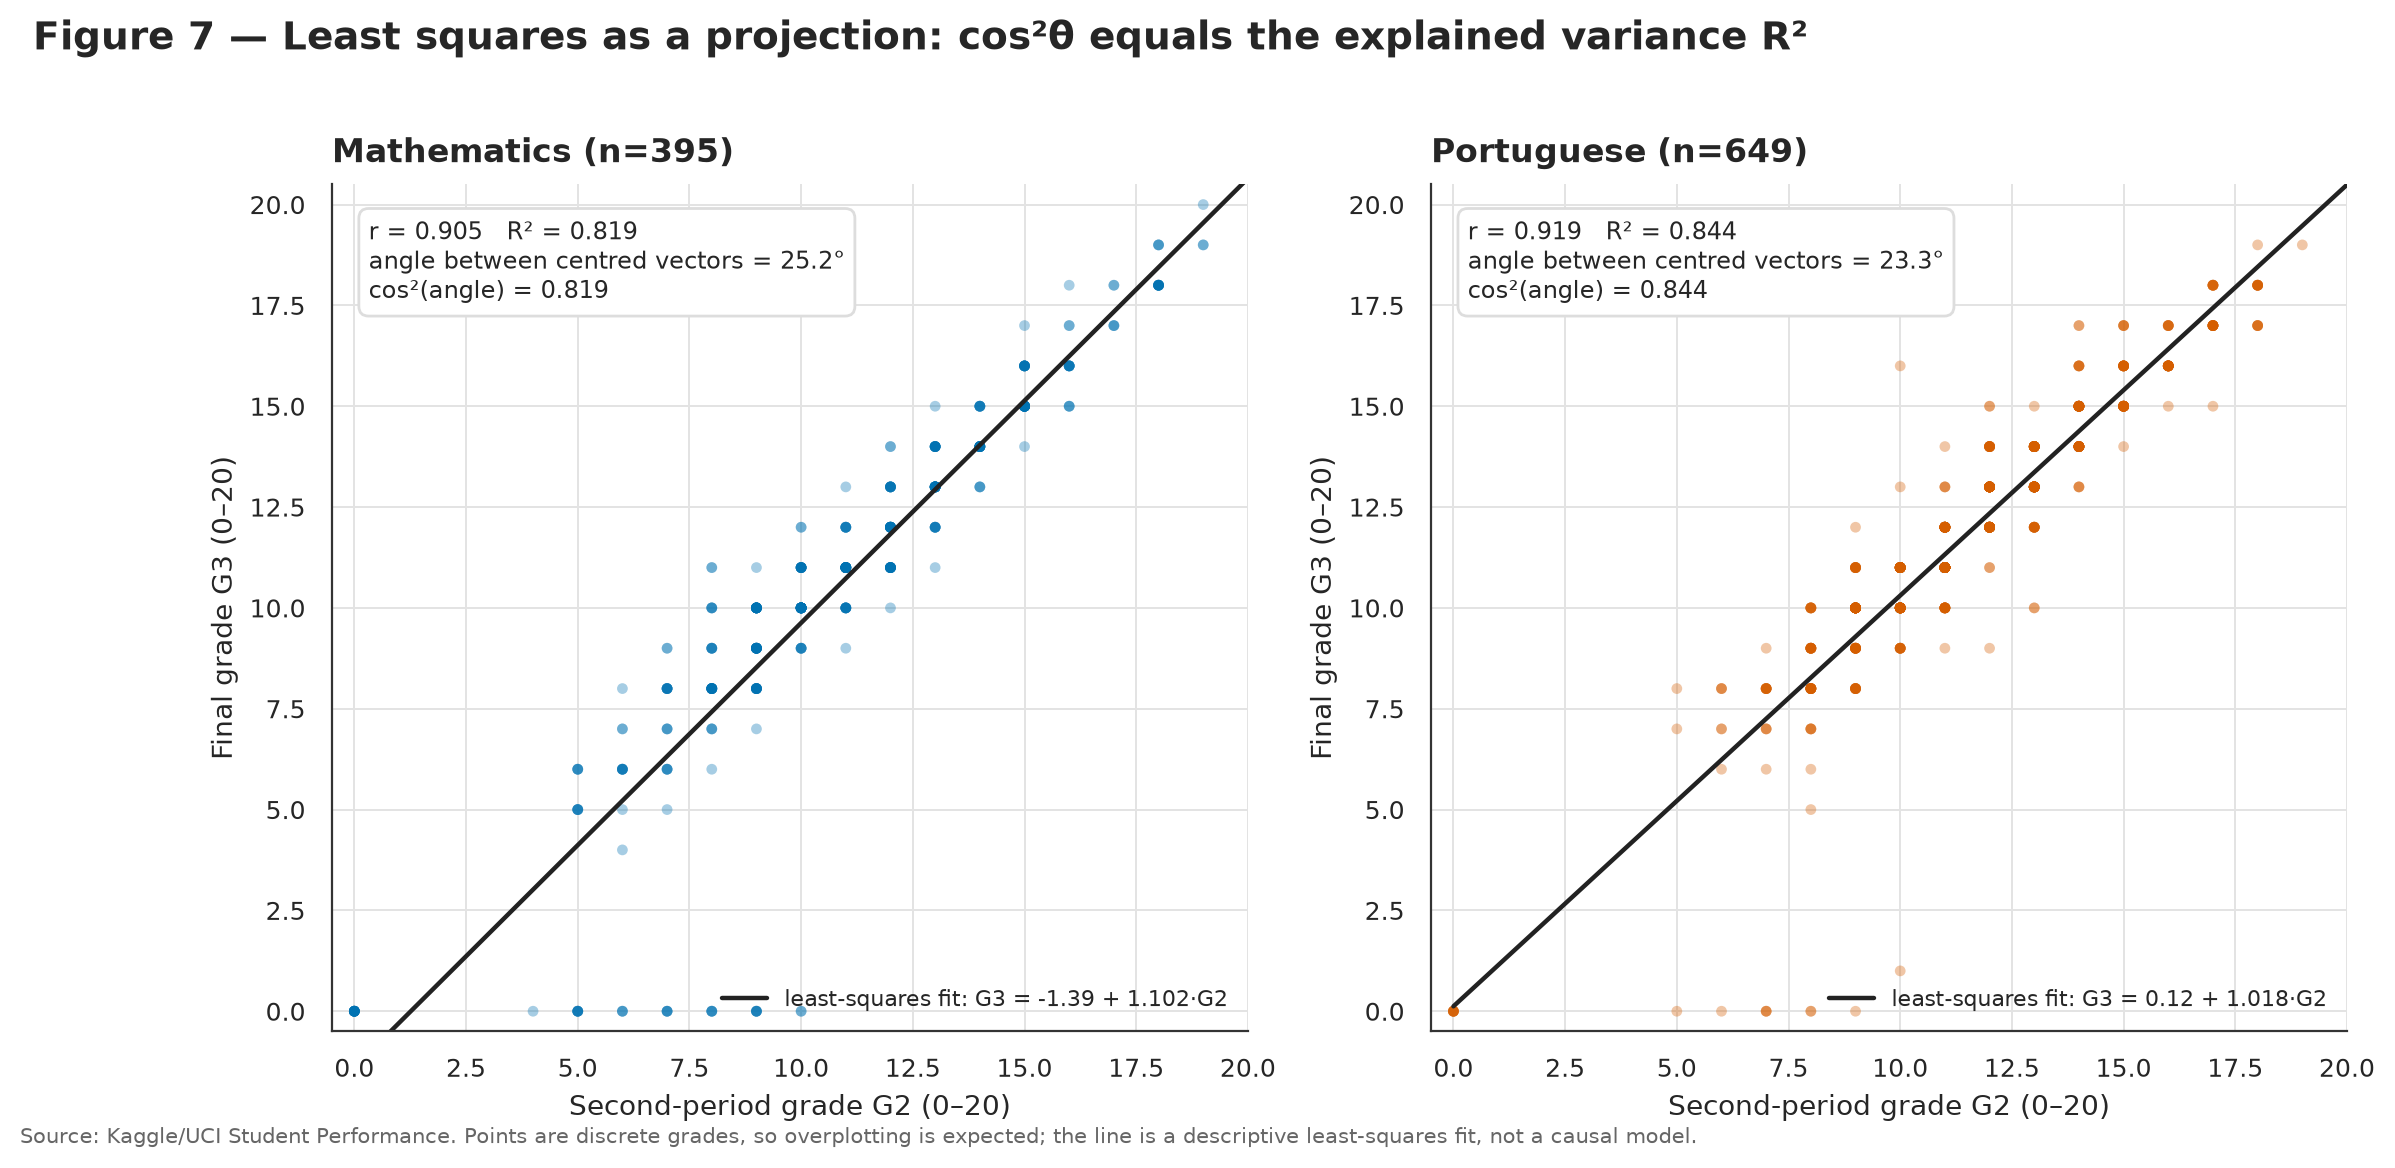

In [12]:
g2_all = df["G2"].to_numpy(dtype=float)
g3_all = df["G3"].to_numpy(dtype=float)
r_all = float(np.corrcoef(g2_all, g3_all)[0, 1])
angle_all = float(np.degrees(np.arccos(np.clip(r_all, -1, 1))))

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.5))
for ax, subject in zip(axes, SUBJECTS):
    g = df[df["subject"] == subject]
    ax.scatter(g["G2"], g["G3"], s=15, alpha=0.35, color=PAL[subject], edgecolors="none")
    slope, intercept = np.polyfit(g["G2"], g["G3"], 1)
    xs = np.array([0, 20])
    ax.plot(xs, intercept + slope * xs, color="#222222", linewidth=1.6,
            label=f"least-squares fit: G3 = {intercept:.2f} + {slope:.3f}·G2")
    r, p = stats.pearsonr(g["G2"], g["G3"])
    theta = np.degrees(np.arccos(np.clip(r, -1, 1)))
    ax.text(0.04, 0.96,
            f"r = {r:.3f}   R² = {r**2:.3f}\nangle between centred vectors = {theta:.1f}°\n"
            f"cos²(angle) = {np.cos(np.radians(theta))**2:.3f}",
            transform=ax.transAxes, va="top", fontsize=8.8,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#DDDDDD"))
    ax.set_xlim(-0.5, 20)
    ax.set_ylim(-0.5, 20.5)
    ax.set_xlabel("Second-period grade G2 (0–20)")
    ax.set_ylabel("Final grade G3 (0–20)")
    ax.legend(loc="lower right", fontsize=8)
    panel_title(ax, f"{subject} (n={len(g)})")
fig.suptitle("Figure 7 — Least squares as a projection: cos²θ equals the explained variance R²",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.03)
save_chart(fig, "07_projection_g2_g3.png",
           "Source: Kaggle/UCI Student Performance. Points are discrete grades, so overplotting is expected; "
           "the line is a descriptive least-squares fit, not a causal model.")

display(Image(filename=str(CHARTS / "07_projection_g2_g3.png"), width=1100))

**Projection intuition.** Centre both grade vectors and call them `a` (G2) and `b` (G3).
The least-squares fitted value of G3 is the projection of `b` onto `a`: it is the
closest point to `b` along the line spanned by G2. The cosine of the angle between the
centred vectors equals Pearson's r, and the squared cosine equals R², the share of
variance in G3 explained by the projection. In mathematics r = 0.905 and R² = 0.819;
in Portuguese r = 0.919 and R² = 0.844. The angle is about 25° in mathematics and 23°
in Portuguese.

This is the geometric content of “correlation is the cosine of centred vectors”. It is
also why R² is a proportion: it is a squared cosine, bounded between 0 and 1. But a
projection is only a fit to these observations. It does not say that raising a
student's G2 by one point would raise G3 by the slope: the fit is descriptive, and the
two grades are successive assessments of the same course.

## 11. Five written insights supported by the data

The five statements below are the project's written insights. Each quotes numbers
computed in this notebook and adds the interpretation and the main caveat. The same
text is stored in `docs/INSIGHTS.md`.

### Insight 1 — Final grades differ by cohort in level, spread and lower tail

Mathematics students average 10.42 (SD 4.58) against 11.91 (SD 3.23) in Portuguese.
The mathematics distribution is flatter and has a spike at zero: 9.6% scored 0 versus
2.3%, and 67.1% reached the pass mark versus 84.6%. **Interpretation:** the cohorts are
not interchangeable, and an average grade quoted without the cohort mixes two different
distributions. **Caveat:** this is a descriptive cohort difference, confounded by
school composition and selection (Insight 4).

### Insight 2 — Attendance is only weakly related to grades, and not monotonically

The grade–absence correlation is +0.034 in mathematics (p = 0.497) and −0.091 in
Portuguese (p = 0.020); pooled r = −0.046 with a bootstrap 95% CI of −0.103 to +0.009.
In mathematics, students with zero absences average 8.44, below the 11.96 of students
with 1–2 absences. **Interpretation:** “more absences, lower grades” is not a simple
rule in these data; the relationship is weak, cohort-specific and non-monotonic.
**Caveat:** reverse causality and selection are plausible; absences are a proxy for
attendance, not a manipulation.

### Insight 3 — Study time tracks grades more clearly in Portuguese; past failures track them in both

Spearman ρ between study time and G3 is 0.105 in mathematics (p = 0.037; Kruskal–Wallis
p = 0.056) and 0.275 in Portuguese (p < 0.001). Mean G3 rises from 10.84 to 13.23 across
Portuguese study bands, but only from 10.05 to 11.40 in mathematics. Past failures show
a stronger, consistent gradient: ρ = −0.361 (mathematics) and −0.448 (Portuguese), with
means falling from 11.25/12.51 at zero failures to 5.69/8.07 at three or more.
**Interpretation:** the behavioural signal is real but context-dependent; prior failure
is a stronger marker than self-reported study time. **Caveat:** study time is coarse and
self-reported, and failures are a prior-attainment proxy, not a lever.

### Insight 4 — The two cohorts are different samples, so the raw gap is not a subject effect

The MS school accounts for 34.8% of the Portuguese cohort but only 11.6% of the
mathematics cohort; paid classes are taken by 6.0% versus 45.8%. Within GP the grade gap
is 2.09 points (12.58 vs 10.49); within MS it is 0.80 points (10.65 vs 9.85). The raw gap
is 1.49 points. **Interpretation:** school and selection are entangled with subject
cohort; standardising to a common school mix raises the gap to about 1.75 points.
**Caveat:** the original merge keys produce 382 matched rows but only 187 distinct
mathematics grade triples, so the data are not a clean paired panel.

### Insight 5 — Prior grade dominates, and correlation does not establish causation

G2 correlates with G3 at 0.905 (mathematics) and 0.919 (Portuguese), explaining 81.9%
and 84.4% of variance. Adding absences, study time and failures raises R² only to 0.826
and 0.847, and the standardised study-time coefficients are −0.03 and +0.03. Paid
tuition shows no significant raw advantage (mathematics 10.92 vs 9.99, p = 0.227;
Portuguese 11.21 vs 11.95, p = 0.149), but uptake is heavily selected. **Interpretation:**
the strongest correlate is the previous grade in the same course, which is partly
mechanical; observational correlations here cannot identify causal effects.
**Caveat:** absence of a significant raw difference is not evidence that tutoring is
ineffective.

**Overall conclusion.** These data are useful for describing a real student cohort and
for practising statistical and linear-algebra reasoning. They are not a basis for
causal claims about attendance, study time or tutoring, and they do not represent a
random sample of students beyond these two schools.

## 12. Spreadsheet cross-check

A separate workbook, `spreadsheet/B6_statistics_crosscheck.xlsx`, recomputes selected
statistics with **live spreadsheet formulas** (COUNT, AVERAGE, MEDIAN, STDEV,
QUARTILE.INC, COUNTIF, CORREL, AVERAGEIF, SUMPRODUCT, SUMSQ, SQRT). The workbook
contains the analysis columns, the formulas, a worked cosine-similarity example, and a
comparison sheet that subtracts the Python value from the spreadsheet value.

The workbook is recalculated in this notebook with the free `formulas` engine
(version 1.3.4), because Excel/LibreOffice is not assumed to be installed. The
comparison tolerance is 1 × 10⁻⁹. The same check can be repeated by opening the file in
Excel or LibreOffice: formulas recalculate on open.

In [13]:
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

book_path = SHEETS / "B6_statistics_crosscheck.xlsx"
wb = openpyxl.Workbook()
wb.remove(wb.active)

header_fill = PatternFill("solid", fgColor="1F4E79")
header_font = Font(color="FFFFFF", bold=True)
title_font = Font(size=13, bold=True, color="1F4E79")
thin = Side(style="thin", color="D9D9D9")
box = Border(left=thin, right=thin, top=thin, bottom=thin)

def style_header(ws, row, values):
    for col, value in enumerate(values, start=1):
        cell = ws.cell(row=row, column=col, value=value)
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        cell.border = box

def data_sheet(name, frame):
    ws = wb.create_sheet(name)
    cols = ["student_id", "G1", "G2", "G3", "absences", "studytime", "failures"]
    ws.append(cols)
    style_header(ws, 1, cols)
    for record in frame[cols].itertuples(index=False, name=None):
        ws.append([record[0]] + [int(v) for v in record[1:]])
    for col in range(1, len(cols) + 1):
        ws.column_dimensions[get_column_letter(col)].width = 13
    ws.freeze_panes = "A2"
    return ws.max_row

math_last = data_sheet("Math_Data", mat)
por_last = data_sheet("Por_Data", por)

readme_ws = wb.create_sheet("README", 0)
readme_ws["A1"] = "B6 spreadsheet cross-check — Student Performance"
readme_ws["A1"].font = title_font
readme_ws["A2"] = ("This workbook recomputes selected statistics from the raw CSV files with live formulas. "
                   "It is a cross-check, not a second analysis pipeline.")
readme_ws["A3"] = "Source: https://www.kaggle.com/datasets/uciml/student-alcohol-consumption (UCI Student Performance)."
readme_ws["A4"] = "Sheets: Math_Data and Por_Data hold analysis columns; Summary, Correlations, Group_Means and Similarity hold formulas."
readme_ws["A5"] = "Comparison subtracts the Python value from the spreadsheet value; tolerance is 1E-09."
readme_ws["A6"] = "Formulas recalculate automatically in Excel or LibreOffice. In this project they were checked with the free 'formulas' engine."
readme_ws.column_dimensions["A"].width = 130

summary_ws = wb.create_sheet("Summary")
summary_ws["A1"] = "Selected statistics — live spreadsheet formulas"
summary_ws["A1"].font = title_font
summary_ws["A2"] = "G3 is the final grade (0–20). n, mean, median, SD, quartiles, pass rate and zero-absence share."
style_header(summary_ws, 4, ["Metric", "Mathematics", "Portuguese", "Difference (Math − Por)"])
summary_specs = [
    ("n students", "COUNT", None),
    ("Mean G3", "AVERAGE", None),
    ("Median G3", "MEDIAN", None),
    ("SD G3 (sample)", "STDEV", None),
    ("Minimum G3", "MIN", None),
    ("Q1 G3", "QUARTILE.INC", 1),
    ("Q3 G3", "QUARTILE.INC", 3),
    ("Maximum G3", "MAX", None),
    ("% G3 >= 10", "PASS", None),
    ("% zero absences", "ZERO", None),
]

def g3_range(sheet, last):
    return f"{sheet}!$D$2:$D${last}"

def abs_range(sheet, last):
    return f"{sheet}!$E$2:$E${last}"

for row_offset, (label, func, extra) in enumerate(summary_specs, start=5):
    summary_ws.cell(row=row_offset, column=1, value=label)
    for col_letter, sheet, last in [("B", "Math_Data", math_last), ("C", "Por_Data", por_last)]:
        if func == "COUNT":
            formula = f"=COUNT({g3_range(sheet, last)})"
        elif func == "AVERAGE":
            formula = f"=AVERAGE({g3_range(sheet, last)})"
        elif func == "MEDIAN":
            formula = f"=MEDIAN({g3_range(sheet, last)})"
        elif func == "STDEV":
            formula = f"=STDEV({g3_range(sheet, last)})"
        elif func == "MIN":
            formula = f"=MIN({g3_range(sheet, last)})"
        elif func == "MAX":
            formula = f"=MAX({g3_range(sheet, last)})"
        elif func == "QUARTILE.INC":
            formula = f"=QUARTILE.INC({g3_range(sheet, last)},{extra})"
        elif func == "PASS":
            formula = f"=COUNTIF({g3_range(sheet, last)},\">=10\")/COUNT({g3_range(sheet, last)})"
        elif func == "ZERO":
            formula = f"=COUNTIF({abs_range(sheet, last)},0)/COUNT({abs_range(sheet, last)})"
        summary_ws[f"{col_letter}{row_offset}"] = formula
    summary_ws[f"D{row_offset}"] = f"=B{row_offset}-C{row_offset}"

for row in range(5, 15):
    summary_ws[f"A{row}"].border = box
    for col in "BCD":
        summary_ws[f"{col}{row}"].border = box
    if row in (9, 10, 11, 12):
        for col in "BCD":
            summary_ws[f"{col}{row}"].number_format = "0.000"
    if row in (13, 14):
        for col in "BCD":
            summary_ws[f"{col}{row}"].number_format = "0.0%"
    if row in (5,):
        for col in "BCD":
            summary_ws[f"{col}{row}"].number_format = "0"
summary_ws.column_dimensions["A"].width = 24
for col in "BCD":
    summary_ws.column_dimensions[col].width = 20

corr_ws = wb.create_sheet("Correlations")
corr_ws["A1"] = "Pearson correlations with G3 — live CORREL formulas"
corr_ws["A1"].font = title_font
style_header(corr_ws, 3, ["Pair", "Mathematics", "Portuguese"])
corr_specs = [
    ("G3 vs G2", "C"),
    ("G3 vs absences", "E"),
    ("G3 vs studytime", "F"),
    ("G3 vs failures", "G"),
]
for offset, (label, column) in enumerate(corr_specs, start=4):
    corr_ws.cell(row=offset, column=1, value=label)
    corr_ws.cell(row=offset, column=2,
                 value=f"=CORREL(Math_Data!$D$2:$D${math_last},Math_Data!${column}$2:${column}${math_last})")
    corr_ws.cell(row=offset, column=3,
                 value=f"=CORREL(Por_Data!$D$2:$D${por_last},Por_Data!${column}$2:${column}${por_last})")
    for col in "ABC":
        corr_ws[f"{col}{offset}"].border = box
    for col in "BC":
        corr_ws[f"{col}{offset}"].number_format = "0.000"
corr_ws.column_dimensions["A"].width = 22
corr_ws.column_dimensions["B"].width = 16
corr_ws.column_dimensions["C"].width = 16

group_ws = wb.create_sheet("Group_Means")
group_ws["A1"] = "Mean G3 by study-time band — live COUNTIF/AVERAGEIF formulas"
group_ws["A1"].font = title_font
style_header(group_ws, 3, ["Study-time band", "Math n", "Math mean G3", "Por n", "Por mean G3"])
for offset, band in enumerate([1, 2, 3, 4], start=4):
    group_ws.cell(row=offset, column=1, value=band)
    group_ws.cell(row=offset, column=2,
                  value=f"=COUNTIF(Math_Data!$F$2:$F${math_last},$A{offset})")
    group_ws.cell(row=offset, column=3,
                  value=f"=AVERAGEIF(Math_Data!$F$2:$F${math_last},$A{offset},Math_Data!$D$2:$D${math_last})")
    group_ws.cell(row=offset, column=4,
                  value=f"=COUNTIF(Por_Data!$F$2:$F${por_last},$A{offset})")
    group_ws.cell(row=offset, column=5,
                  value=f"=AVERAGEIF(Por_Data!$F$2:$F${por_last},$A{offset},Por_Data!$D$2:$D${por_last})")
    for col in "ABCDE":
        group_ws[f"{col}{offset}"].border = box
    for col in "CE":
        group_ws[f"{col}{offset}"].number_format = "0.000"
for col, width in zip("ABCDE", [16, 10, 15, 10, 15]):
    group_ws.column_dimensions[col].width = width

sim_ws = wb.create_sheet("Similarity")
sim_ws["A1"] = "Worked cosine similarity — live SUMPRODUCT/SUMSQ formulas"
sim_ws["A1"].font = title_font
sim_ws["A2"] = "MAT-001 vs MAT-019 on G1, G2, G3, absences and studytime."
style_header(sim_ws, 4, ["Feature", "MAT-001", "MAT-019", "Difference"])
sim_features = ["G1", "G2", "G3", "absences", "studytime"]
sim_a = df.loc[df["student_id"] == "MAT-001", sim_features].iloc[0].to_numpy(dtype=int)
sim_b = df.loc[df["student_id"] == "MAT-019", sim_features].iloc[0].to_numpy(dtype=int)
for offset, (feature, a, b) in enumerate(zip(sim_features, sim_a, sim_b), start=5):
    sim_ws.cell(row=offset, column=1, value=feature)
    sim_ws.cell(row=offset, column=2, value=int(a))
    sim_ws.cell(row=offset, column=3, value=int(b))
    sim_ws.cell(row=offset, column=4, value=f"=B{offset}-C{offset}")
    for col in "ABCD":
        sim_ws[f"{col}{offset}"].border = box

sim_ws["A11"] = "Dot product"
sim_ws["B11"] = "=SUMPRODUCT(B5:B9,C5:C9)"
sim_ws["A12"] = "Norm MAT-001"
sim_ws["B12"] = "=SQRT(SUMSQ(B5:B9))"
sim_ws["A13"] = "Norm MAT-019"
sim_ws["B13"] = "=SQRT(SUMSQ(C5:C9))"
sim_ws["A14"] = "Cosine similarity (raw)"
sim_ws["B14"] = "=B11/(B12*B13)"
sim_ws["A15"] = "Euclidean distance"
sim_ws["B15"] = "=SQRT(SUMSQ(D5:D9))"
sim_ws["A17"] = "Mean of features"
sim_ws["B17"] = "=AVERAGE(B5:B9)"
sim_ws["C17"] = "=AVERAGE(C5:C9)"
sim_ws["A18"] = "Centred values MAT-001 (F) and MAT-019 (G)"
for offset in range(5, 10):
    sim_ws[f"F{offset}"] = f"=B{offset}-$B$17"
    sim_ws[f"G{offset}"] = f"=C{offset}-$C$17"
sim_ws["A19"] = "Dot product of centred vectors"
sim_ws["B19"] = "=SUMPRODUCT(F5:F9,G5:G9)"
sim_ws["A20"] = "Norm centred MAT-001"
sim_ws["B20"] = "=SQRT(SUMSQ(F5:F9))"
sim_ws["A21"] = "Norm centred MAT-019"
sim_ws["B21"] = "=SQRT(SUMSQ(G5:G9))"
sim_ws["A22"] = "Cosine similarity (centred)"
sim_ws["B22"] = "=B19/(B20*B21)"
for row in range(11, 23):
    if sim_ws[f"A{row}"].value:
        sim_ws[f"A{row}"].border = box
        sim_ws[f"B{row}"].border = box
        sim_ws[f"B{row}"].number_format = "0.000"
sim_ws.column_dimensions["A"].width = 34
for col in "BCDEFG":
    sim_ws.column_dimensions[col].width = 13

comparison_ws = wb.create_sheet("Comparison")
comparison_ws["A1"] = "Cross-check: spreadsheet formula value vs independent Python value"
comparison_ws["A1"].font = title_font
comparison_ws["A2"] = "Tolerance 1E-09. Status is generated by an IF formula in column E."
style_header(comparison_ws, 4, ["Check", "Spreadsheet value", "Python value", "Absolute difference", "Status"])

def py_mean(frame, column):
    return float(frame[column].mean())

checks = []
for subject, frame, sheet, last, col in [
    ("Mathematics", mat, "Math_Data", math_last, "B"),
    ("Portuguese", por, "Por_Data", por_last, "C"),
]:
    checks.extend([
        (f"{subject}: n", f"=Summary!{col}5", float(len(frame))),
        (f"{subject}: mean G3", f"=Summary!{col}6", float(frame.G3.mean())),
        (f"{subject}: median G3", f"=Summary!{col}7", float(frame.G3.median())),
        (f"{subject}: SD G3", f"=Summary!{col}8", float(frame.G3.std(ddof=1))),
        (f"{subject}: % G3 >= 10", f"=Summary!{col}13", float((frame.G3 >= 10).mean())),
    ])
for label, row in [("Mathematics", 4), ("Portuguese", 5)]:
    col = "B" if label == "Mathematics" else "C"
    checks.extend([
        (f"{label}: r(G3,G2)", f"=Correlations!{col}4", float(df[df.subject == label][["G2", "G3"]].corr().iloc[0, 1])),
        (f"{label}: r(G3,absences)", f"=Correlations!{col}5", float(df[df.subject == label][["absences", "G3"]].corr().iloc[0, 1])),
    ])
for subject, frame, col_n, col_mean in [("Mathematics", mat, "B", "C"), ("Portuguese", por, "D", "E")]:
    for offset, band in enumerate([1, 2, 3, 4], start=4):
        sub = frame[frame["studytime"] == band]["G3"]
        checks.append((f"{subject}: studytime {band} mean", f"=Group_Means!{col_mean}{offset}", float(sub.mean())))
checks.extend([
    ("MAT-001 vs MAT-019: raw cosine", "=Similarity!B14", cosine_raw),
    ("MAT-001 vs MAT-019: centred cosine", "=Similarity!B22", cosine_centered),
    ("MAT-001 vs MAT-019: Euclidean distance", "=Similarity!B15", euclidean),
])

for offset, (label, formula, python_value) in enumerate(checks, start=5):
    comparison_ws.cell(row=offset, column=1, value=label)
    comparison_ws.cell(row=offset, column=2, value=formula)
    comparison_ws.cell(row=offset, column=3, value=float(python_value))
    comparison_ws.cell(row=offset, column=4, value=f"=ABS(C{offset}-B{offset})")
    comparison_ws.cell(row=offset, column=5, value=f'=IF(D{offset}<=1E-9,"PASS","CHECK")')
    for col in "ABCDE":
        comparison_ws[f"{col}{offset}"].border = box
    comparison_ws[f"B{offset}"].number_format = "0.000000000"
    comparison_ws[f"C{offset}"].number_format = "0.000000000"
    comparison_ws[f"D{offset}"].number_format = "0.00E+00"
comparison_ws.column_dimensions["A"].width = 36
for col in "BCD":
    comparison_ws.column_dimensions[col].width = 20
comparison_ws.column_dimensions["E"].width = 10

wb.save(book_path)
print("Saved workbook:", book_path.relative_to(ROOT))

import formulas
model = formulas.ExcelModel().loads(str(book_path)).finish()
solution = model.calculate()

def read_cell(sheet, address):
    for key in (f"'[{book_path.name}]{sheet.upper()}'!{address}",
                f"'[{book_path.name}]{sheet}'!{address}"):
        if key in solution:
            return float(np.asarray(solution[key].value).ravel()[0])
    raise KeyError(f"Cell not found: {sheet}!{address}")

results = []
for offset, (label, formula, python_value) in enumerate(checks, start=5):
    sheet_part, cell_part = formula.lstrip("=").split("!")
    sheet_value = read_cell(sheet_part, cell_part)
    diff = abs(sheet_value - float(python_value))
    results.append({
        "check": label,
        "spreadsheet_value": sheet_value,
        "python_value": float(python_value),
        "abs_difference": diff,
        "status": "PASS" if diff <= 1e-9 else "CHECK",
    })
crosscheck = pd.DataFrame(results)
crosscheck.to_csv(SHEETS / "crosscheck_results.csv", index=False)
display(crosscheck.round(10))
print("Checks:", len(crosscheck), "| PASS:", int((crosscheck.status == "PASS").sum()),
      "| max abs diff:", f"{crosscheck.abs_difference.max():.2e}")
assert (crosscheck.status == "PASS").all(), "Spreadsheet cross-check failed."

Saved workbook: spreadsheet\B6_statistics_crosscheck.xlsx


  0%|          | 0/15 [00:00<?, ?it/s]

100%|██████████| 15/15 [00:00<00:00, 1214.99it/s]

,check,spreadsheet_value,python_value,abs_difference,status
0,Mathematics: n,395.000,395.000,0.000,PASS
1,Mathematics: mean G3,10.415,10.415,0.000,PASS
2,Mathematics: median G3,11.000,11.000,0.000,PASS
3,Mathematics: SD G3,4.581,4.581,0.000,PASS
4,Mathematics: % G3 >= 10,0.671,0.671,0.000,PASS
5,Portuguese: n,649.000,649.000,0.000,PASS
6,Portuguese: mean G3,11.906,11.906,0.000,PASS
7,Portuguese: median G3,12.000,12.000,0.000,PASS
8,Portuguese: SD G3,3.231,3.231,0.000,PASS
9,Portuguese: % G3 >= 10,0.846,0.846,0.000,PASS


Checks: 25 | PASS: 25 | max abs diff: 1.22e-15


**Cross-check result.** Every selected statistic agrees between the spreadsheet
formulas and the Python calculation to better than 1 × 10⁻⁹. The workbook is
`spreadsheet/B6_statistics_crosscheck.xlsx`; the machine-readable comparison is
`spreadsheet/crosscheck_results.csv`. The check covers sample counts, means, medians,
sample standard deviations, pass rates, Pearson correlations, study-band means and the
worked cosine-similarity example. This is deliberately a *selective* cross-check: it
validates the pipeline and the arithmetic, not every number in the notebook.

## 13. Limitations, ethics and reproducibility

**Design.** The data are observational and come from two Portuguese secondary schools.
There is no random assignment, no control group and no temporal ordering that would
support causal claims about attendance, study time or tutoring. All statements in this
notebook are descriptive or associational.

**Sampling.** The sample is a convenience sample of students in two schools. It is not
representative of Portugal or of students elsewhere. The two subject cohorts differ in
school composition, paid-class uptake and sex composition, so pooled statistics mix
different populations. The 382 approximate matches between files are many-to-many, not
a paired panel.

**Measurement.** Grades are discrete and bounded (0–20), which creates ceiling and floor
effects; G1–G3 are successive assessments of the same course, so their correlations are
partly mechanical. `studytime` is a coarse self-reported band, `failures` is top-coded
at 3, and `absences` is a school-record proxy with a long right tail. Self-report and
school-record errors are not quantified in the data.

**Analysis choices.** Spearman is used for skewed/ordinal variables; Pearson and
bootstrap intervals are reported alongside. The 11 pooled tests involving G3 are
corrected with Benjamini–Hochberg. Group means are shown with 95% confidence intervals,
but small subgroups (for example 14–17 students with two or three failures) remain
imprecise. Charts are descriptive and do not adjust for confounders.

**Ethics.** The data contain no names or direct identifiers. The constructed
`student_id` values are row labels, not real identifiers. Results should not be used to
rank, label or discipline individual students; group-level patterns do not license
individual predictions. Any deployment involving students would require fairness,
privacy and consent review.

**Reproducibility.** Paths are resolved relative to the project root, the random seed is
fixed at 20261113, raw files are checksum-verified, and all derived tables and figures
are written to disk. The notebook is executed from top to bottom in a clean kernel
before submission; `outputs/notebook_execution.log` records the run.

In [14]:
chart_files = sorted(CHARTS.glob("*.png"))
assert len(chart_files) >= 4, "At least four charts are required."
for path in chart_files:
    assert path.stat().st_size > 10_000, f"Chart looks empty: {path}"

versions = pd.DataFrame({
    "component": ["Python", "pandas", "NumPy", "Matplotlib", "Seaborn", "SciPy", "openpyxl", "formulas"],
    "version": [platform.python_version(), pd.__version__, np.__version__, mpl.__version__,
                sns.__version__, __import__("scipy").__version__, openpyxl.__version__, formulas.__version__],
})
versions.to_csv(OUT / "environment_versions.csv", index=False)
display(versions)

print(f"Charts written: {len(chart_files)}")
for path in chart_files:
    print(f"  {path.name:36s} {path.stat().st_size/1024:7.1f} KB")
print("\nProcessed tables:")
for path in sorted(PROC.glob("*.csv")):
    print(f"  {path.name}")
print("\nNotebook completed successfully.")

,component,version
0,Python,3.13.17
1,pandas,3.1.1
2,NumPy,2.5.4
3,Matplotlib,3.11.2
4,Seaborn,0.13.2
5,SciPy,1.18.1
6,openpyxl,3.1.5
7,formulas,1.3.4


Charts written: 7
  01_grade_distributions.png             208.5 KB
  02_attendance_patterns.png             163.8 KB
  03_study_habits_grades.png             176.4 KB
  04_sampling_comparison.png             167.0 KB
  05_correlation_heatmap.png             226.6 KB
  06_vector_similarity.png               168.9 KB
  07_projection_g2_g3.png                204.2 KB

Processed tables:
  attendance_by_band.csv
  cleaning_decisions.csv
  cohort_summary.csv
  correlation_pearson_math.csv
  correlation_pearson_portuguese.csv
  correlation_spearman_math.csv
  correlation_spearman_portuguese.csv
  correlation_tests_pooled.csv
  summary_statistics.csv

Notebook completed successfully.


## 14. References

1. Cortez, P., & Silva, A. (2008). *Using data mining to predict secondary school
   student performance.* In Proceedings of the 5th FUBUTEC Conference (pp. 5–12),
   Porto, Portugal. EUROSIS. ISBN 978-9077381-39-7.
2. Kaggle dataset: *Student Alcohol Consumption*, UCI Machine Learning mirror.
   https://www.kaggle.com/datasets/uciml/student-alcohol-consumption
3. UCI Machine Learning Repository: *Student Performance* (ID 320).
   https://archive.ics.uci.edu/dataset/320/student+performance
   DOI: https://doi.org/10.24432/C5TG7T (CC BY 4.0).
4. Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a
   practical and powerful approach to multiple testing. *Journal of the Royal
   Statistical Society: Series B, 57*(1), 289–300.
5. Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap.*
   Chapman & Hall/CRC.